In [3]:
import numpy as np
for i in range(1, 11):
    # Load data
    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_flow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )
    sim_flow_old= np.squeeze(sim_flow_old)
    sim_flow_new= np.squeeze(sim_flow_new)
    sim_gwflow_old= np.squeeze(sim_gwflow_old)
    sim_gwflow_new= np.squeeze(sim_gwflow_new)


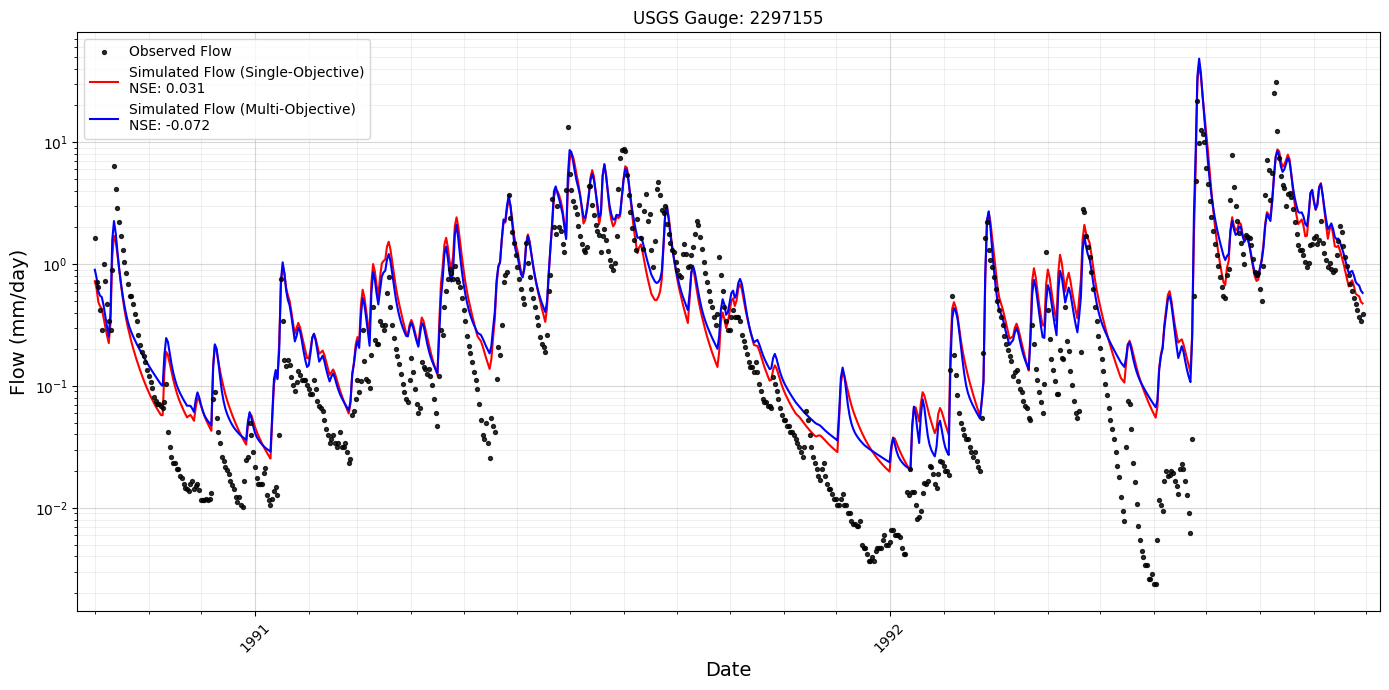

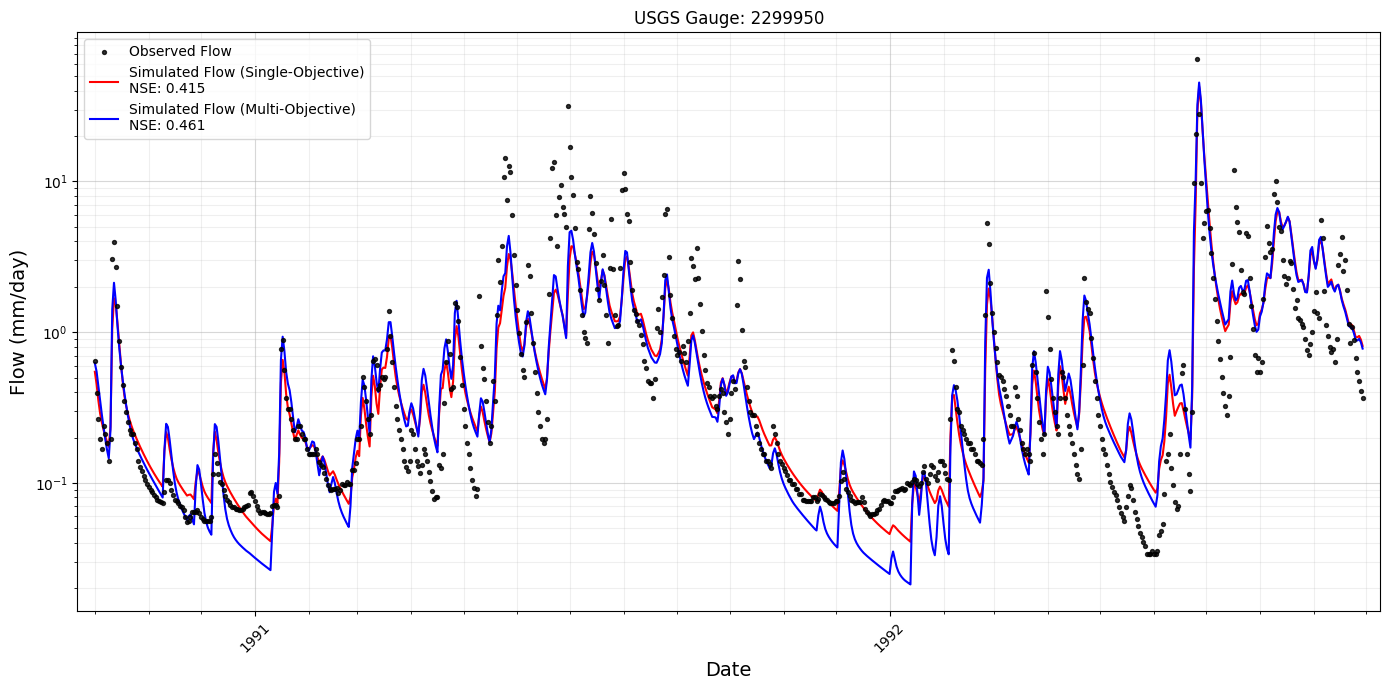

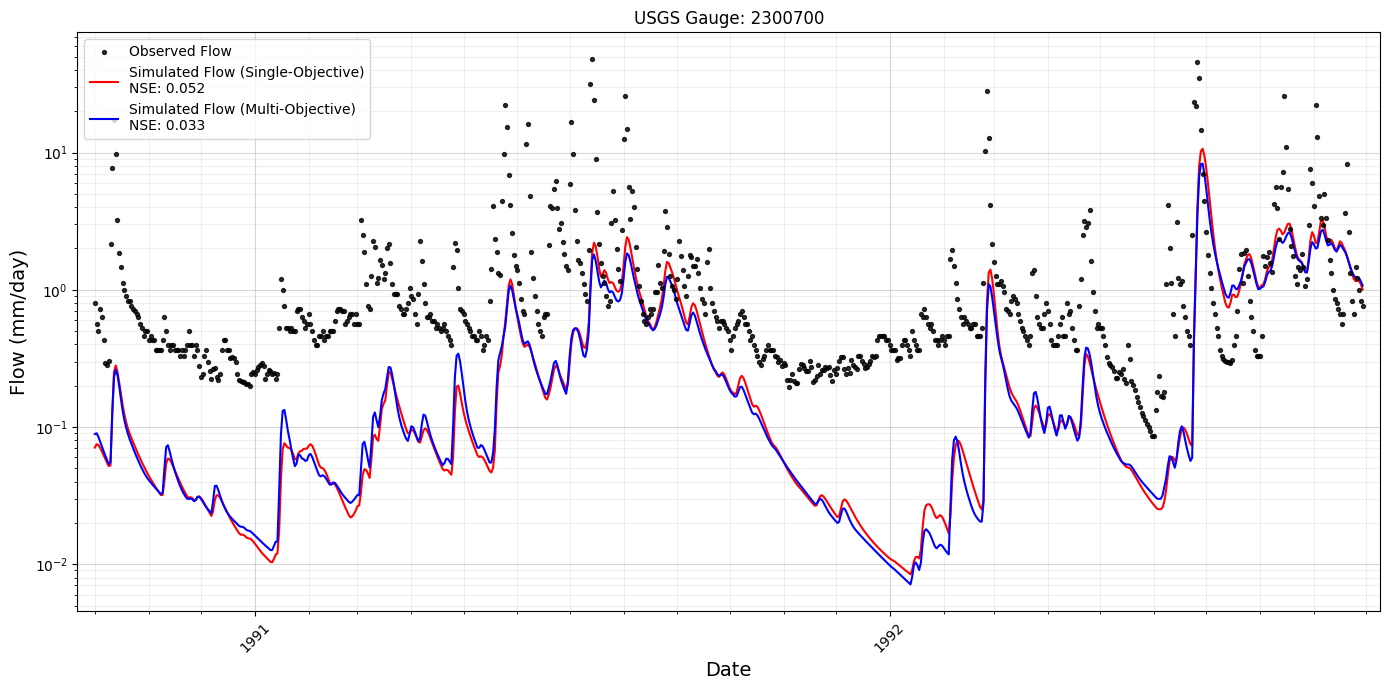

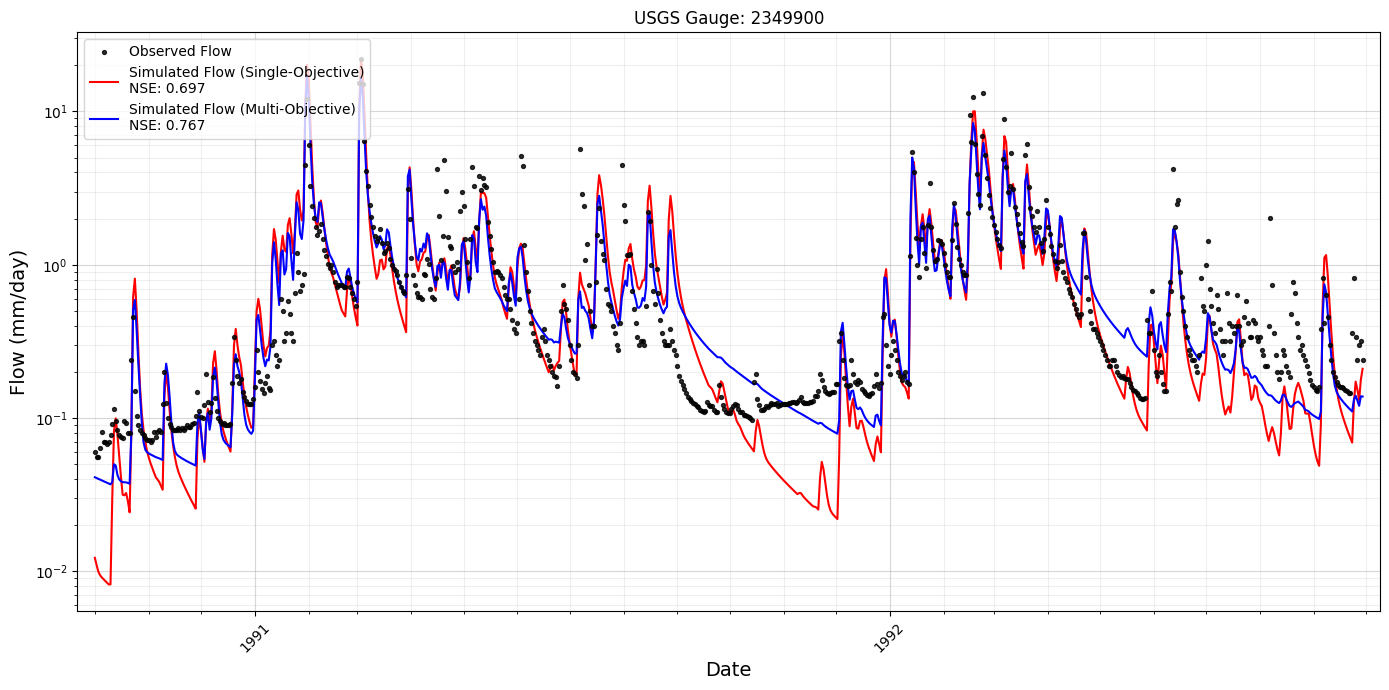

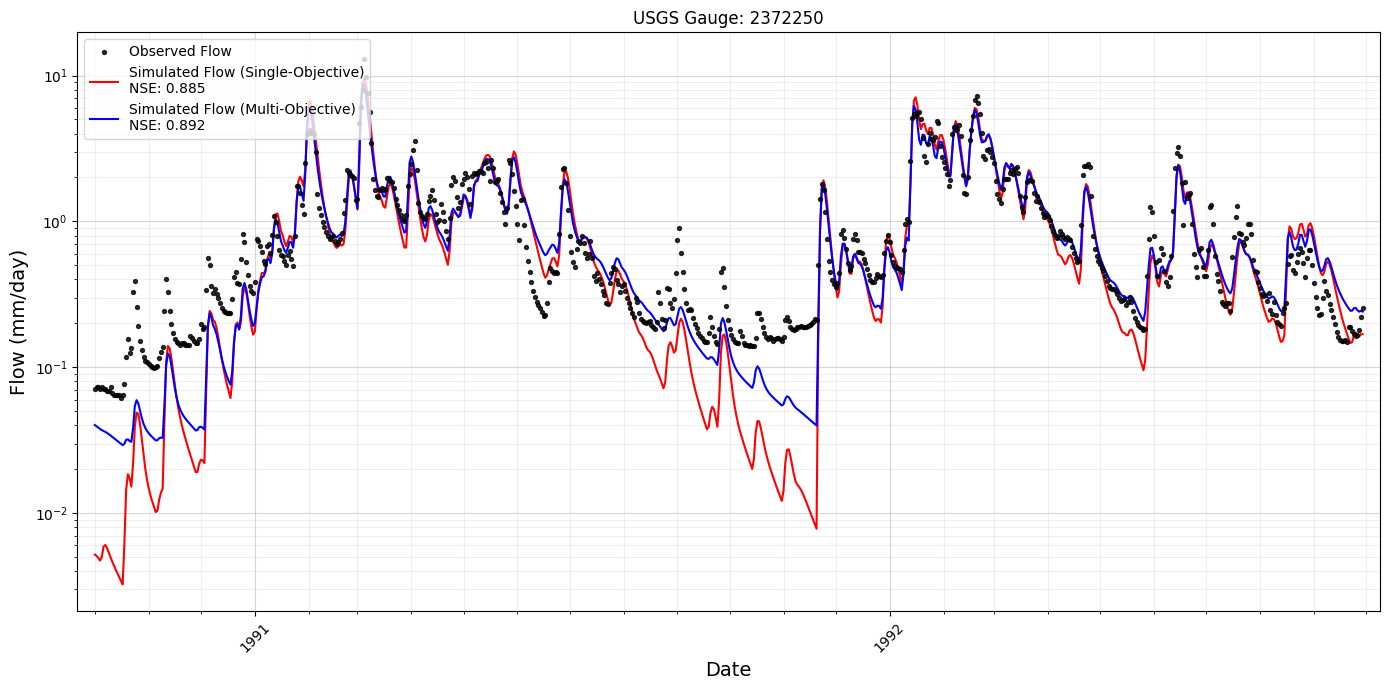

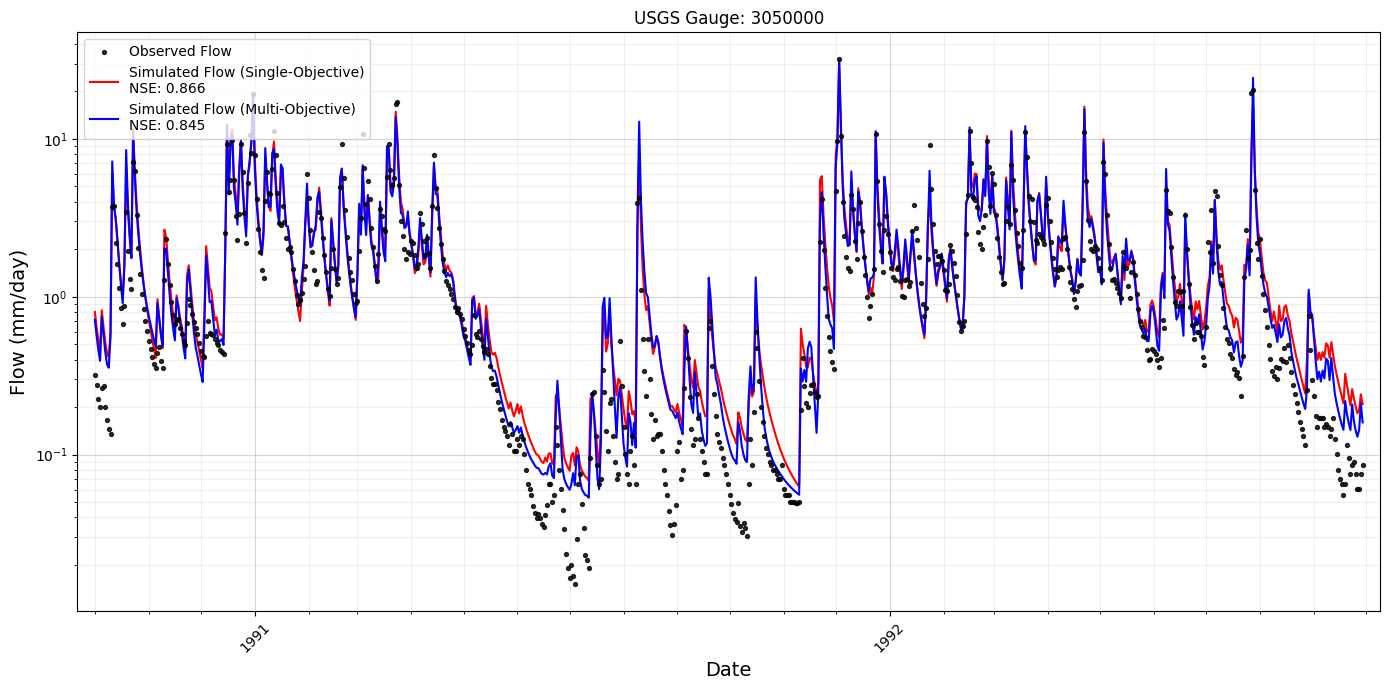

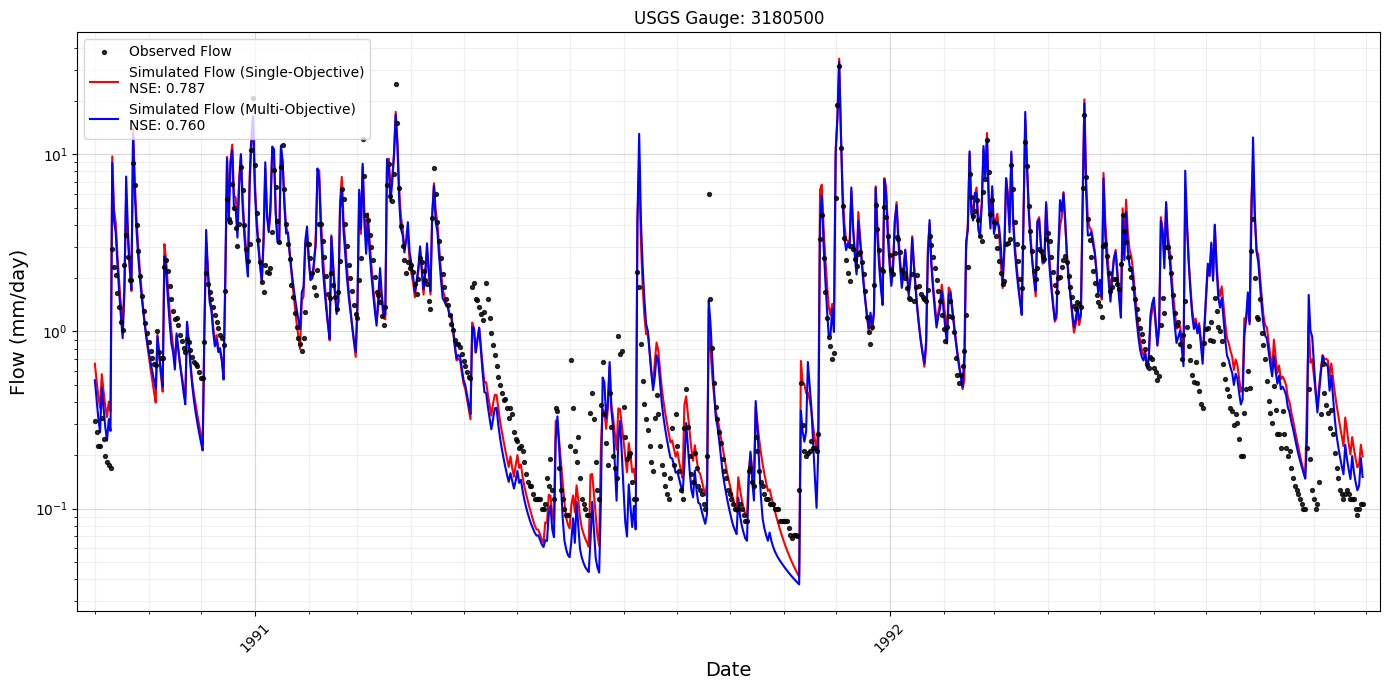

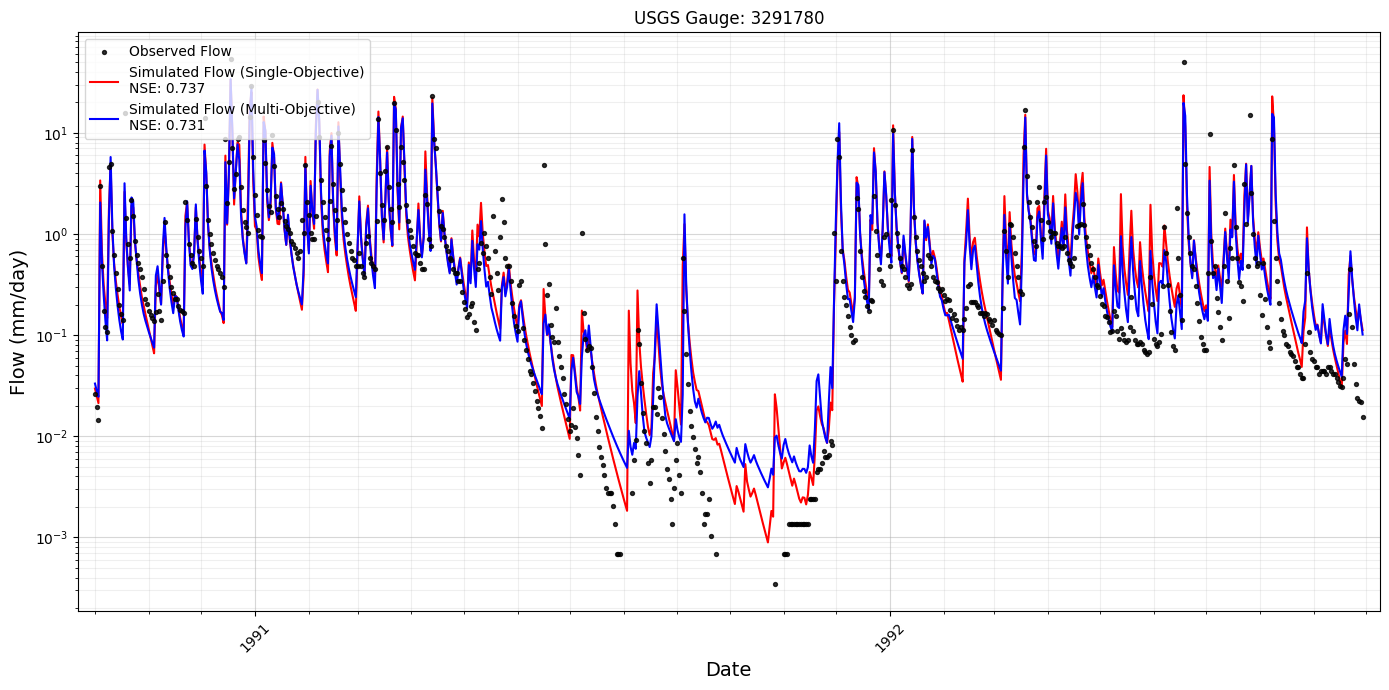

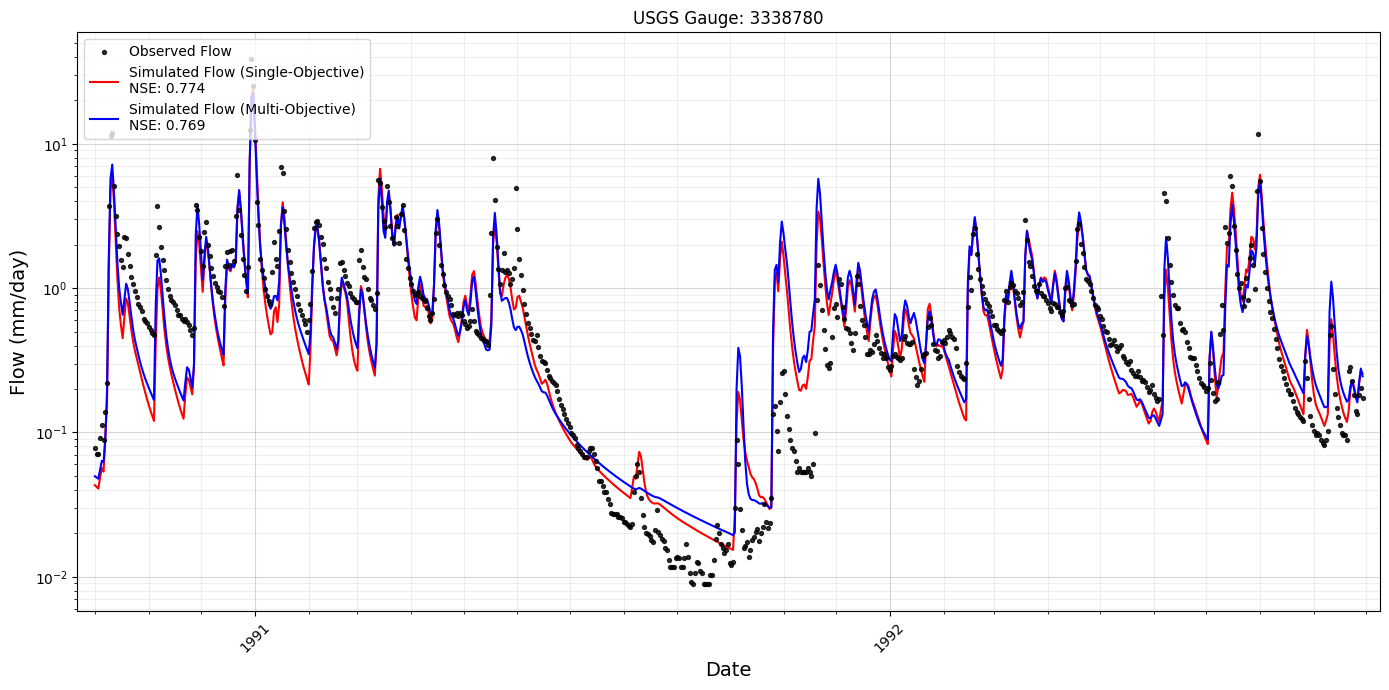

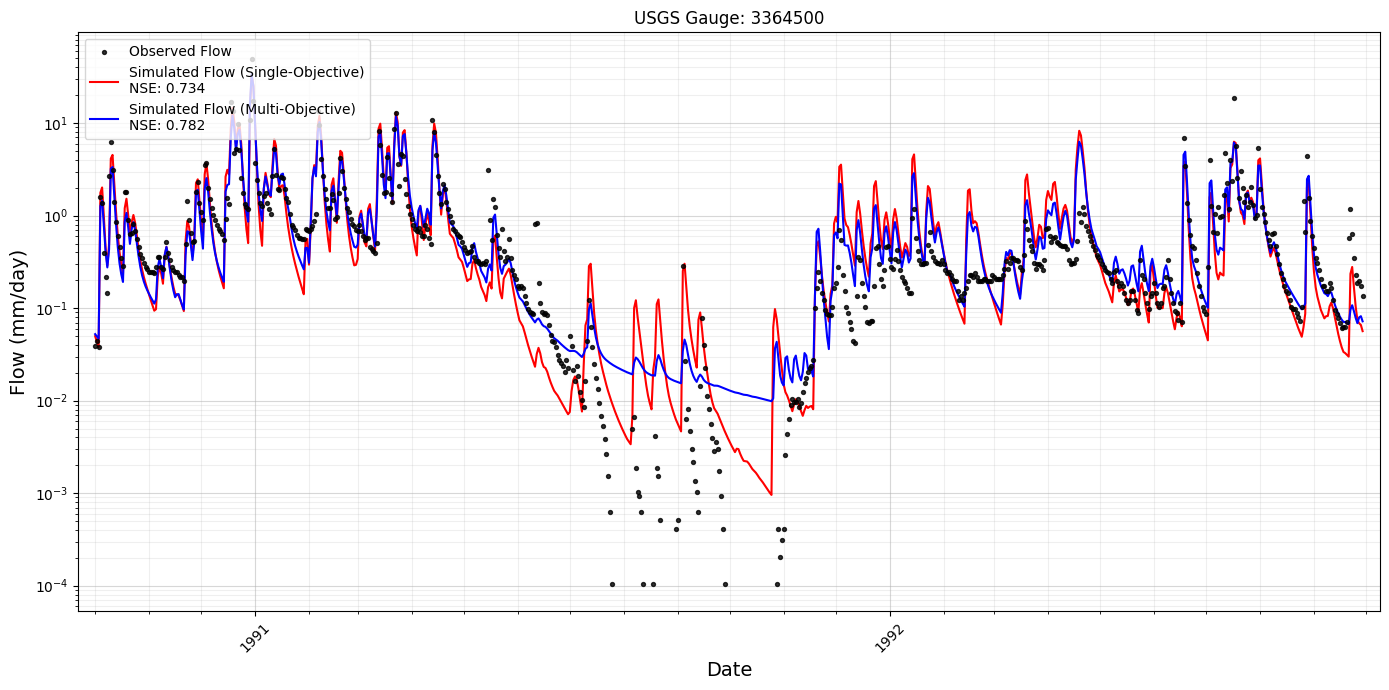

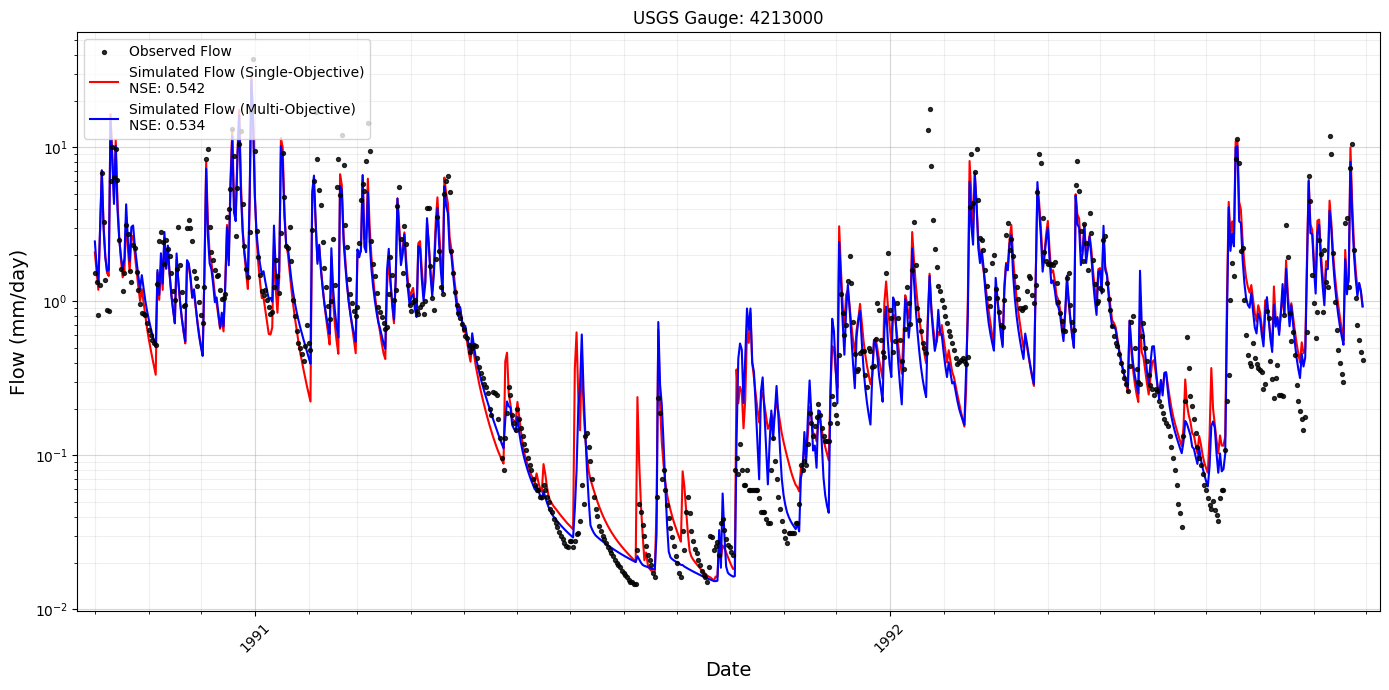

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
from pandas import Timedelta

# ----------------------------------------
# Load gauge IDs
# ----------------------------------------
gauge = np.load(
    "/home/s0shar47/scratch/BASEFLOW_FOLDS/10/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
)
# ----------------------------------------
# Date axis
# ----------------------------------------

# ----------------------------------------
# Plot first 10 basins
# ----------------------------------------
for i in range(10,21):


    fig, ax = plt.subplots(figsize=(14, 7))

    gid = int(gauge[i, 0, -2])

    obs = ob_flow[0:730, i].copy()
    sim_old = sim_flow_old[0:730, i].copy()
    sim_new = sim_flow_new[0:730, i].copy()
    dates = pd.date_range(
    start="1990-10-01",
    periods=obs.shape[0],
    freq="D"
)


    den= np.sum((obs - obs.mean()) ** 2)
    num1= np.sum((obs - sim_old) ** 2)
    num2= np.sum((obs - sim_new) ** 2)

    nse1= 1- num1/den
    nse2= 1-num2/den

    # Replace non-positive values with NaN for log scale
    obs[obs <= 0] = np.nan
    sim_old[sim_old <= 0] = np.nan
    sim_new[sim_new <= 0] = np.nan

    # Observations as scatter
    ax.scatter(
        dates,
        obs,
        color="black",
        s=8,
        alpha=0.8,
        label="Observed Flow",
        zorder=3,
    )

    # Simulations as lines
    ax.plot(
        dates,
        sim_old,
        color="red",
        linewidth=1.5,
        label= f"Simulated Flow (Single-Objective)\nNSE: {nse1:.3f}",
        zorder=2,
    )

    ax.plot(
        dates,
        sim_new,
        color="blue",
        linewidth=1.5,
        label= f"Simulated Flow (Multi-Objective)\nNSE: {nse2:.3f}",
        zorder=2,
    )

    # Logarithmic y-axis
    ax.set_yscale("log")

    # Add padding
    buffer = Timedelta(days=10)
    ax.set_xlim(dates[0] - buffer, dates[-1] + buffer)

    # Year ticks
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())

    plt.xticks(rotation=45)

    ax.set_xlabel("Date", fontsize=14)
    ax.set_ylabel("Flow (mm/day)", fontsize=14)
    ax.set_title(f"USGS Gauge: {gid}")

    ax.grid(True, which="major", alpha=0.5)
    ax.grid(True, which="minor", alpha=0.2)

    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np

# ============================================================
# Metric functions
# ============================================================

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


# ============================================================
# Containers
# ============================================================

metrics_old = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

metrics_new = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

# ============================================================
# Loop over folds
# ============================================================

for i in range(1, 11):

    obs_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/00060_Mean.npy"
    )

    sim_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    )

    sim_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    )

    sim_old = np.squeeze(sim_old)
    sim_new = np.squeeze(sim_new)

    # --------------------------------------------------------
    # Loop over basins
    # --------------------------------------------------------
    for k in range(obs_flow.shape[1]):

        obs = obs_flow[:, k]
        old = sim_old[:, k]
        new = sim_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics_old["NSE"].append(calc_nse(obs, old))
        metrics_new["NSE"].append(calc_nse(obs, new))

        metrics_old["KGE"].append(calc_kge(obs, old))
        metrics_new["KGE"].append(calc_kge(obs, new))

        metrics_old["Bias"].append(calc_bias(obs, old))
        metrics_new["Bias"].append(calc_bias(obs, new))

        metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
        metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

        # =====================================================
        # Low / High flow
        # =====================================================
        threshold = np.median(obs)

        low = obs <= threshold
        high = obs > threshold

        # ---------------- Low flow ----------------
        if np.sum(low) > 2:

            metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
            metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

            metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
            metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

            metrics_old["AbsBias_low"].append(
                calc_abs_bias(obs[low], old[low])
            )
            metrics_new["AbsBias_low"].append(
                calc_abs_bias(obs[low], new[low])
            )

        # ---------------- High flow ----------------
        if np.sum(high) > 2:

            metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
            metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

            metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
            metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

            metrics_old["AbsBias_high"].append(
                calc_abs_bias(obs[high], old[high])
            )
            metrics_new["AbsBias_high"].append(
                calc_abs_bias(obs[high], new[high])
            )

# ============================================================
# Print comparison
# ============================================================

print("\n" + "=" * 60)
print("TOTAL FLOW COMPARISON (Entire Timeline 1980-01-01, 2014-12-31)")
print("=" * 60)

metric_order = [
    "NSE",
    "KGE",
    "Bias",
    "AbsBias",
    "NSE_low",
    "NSE_high",
    "Bias_low",
    "Bias_high",
    "AbsBias_low",
    "AbsBias_high",
]

for metric in metric_order:
    old = np.nanmedian(metrics_old[metric])
    new = np.nanmedian(metrics_new[metric])
    print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

print("=" * 60)


TOTAL FLOW COMPARISON (Entire Timeline 1980-01-01, 2014-12-31)
NSE          :   0.5856 →   0.5771
KGE          :   0.6125 →   0.5968
Bias         :   0.0363 →   0.0094
AbsBias      :   0.1200 →   0.1156
NSE_low      :  -0.5651 →  -0.4822
NSE_high     :   0.6163 →   0.6159
Bias_low     :   0.1198 →   0.0693
Bias_high    :  -0.0279 →  -0.0402
AbsBias_low  :   0.2433 →   0.2270
AbsBias_high :   0.1177 →   0.1172


: 

In [16]:
import numpy as np

# ============================================================
# Metric functions
# ============================================================

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


# ============================================================
# Containers
# ============================================================

metrics_old = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

metrics_new = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

# ============================================================
# Loop over folds
# ============================================================

for i in range(1, 11):

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/baseflow.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    )

    sim_gwflow_old = np.squeeze(sim_gwflow_old)
    sim_gwflow_new = np.squeeze(sim_gwflow_new)

    # --------------------------------------------------------
    # Loop over basins
    # --------------------------------------------------------
    for k in range(ob_baseflow.shape[1]):

        obs = ob_baseflow[:, k]
        old = sim_gwflow_old[:, k]
        new = sim_gwflow_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics_old["NSE"].append(calc_nse(obs, old))
        metrics_new["NSE"].append(calc_nse(obs, new))

        metrics_old["KGE"].append(calc_kge(obs, old))
        metrics_new["KGE"].append(calc_kge(obs, new))

        metrics_old["Bias"].append(calc_bias(obs, old))
        metrics_new["Bias"].append(calc_bias(obs, new))

        metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
        metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

        # =====================================================
        # Low / High flow
        # =====================================================
        threshold = np.median(obs)

        low = obs <= threshold
        high = obs > threshold

        # ---------------- Low flow ----------------
        if np.sum(low) > 2:

            metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
            metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

            metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
            metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

            metrics_old["AbsBias_low"].append(
                calc_abs_bias(obs[low], old[low])
            )
            metrics_new["AbsBias_low"].append(
                calc_abs_bias(obs[low], new[low])
            )

        # ---------------- High flow ----------------
        if np.sum(high) > 2:

            metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
            metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

            metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
            metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

            metrics_old["AbsBias_high"].append(
                calc_abs_bias(obs[high], old[high])
            )
            metrics_new["AbsBias_high"].append(
                calc_abs_bias(obs[high], new[high])
            )

# ============================================================
# Print comparison
# ============================================================

print("\n" + "=" * 60)
print("GROUNDWATER / BASEFLOW COMPARISON (Entire Timeline 1980-01-01, 2014-12-31)")
print("=" * 60)

metric_order = [
    "NSE",
    "KGE",
    "Bias",
    "AbsBias",
    "NSE_low",
    "NSE_high",
    "Bias_low",
    "Bias_high",
    "AbsBias_low",
    "AbsBias_high",
]

for metric in metric_order:
    old = np.nanmedian(metrics_old[metric])
    new = np.nanmedian(metrics_new[metric])
    print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

print("=" * 60)


GROUNDWATER / BASEFLOW COMPARISON (Entire Timeline 1980-01-01, 2014-12-31)
NSE          :   0.4226 →   0.6677
KGE          :   0.4882 →   0.6574
Bias         :   0.2347 →   0.0477
AbsBias      :   0.3183 →   0.1934
NSE_low      :  -6.9608 →  -2.2419
NSE_high     :   0.1746 →   0.4552
Bias_low     :   0.7688 →   0.3572
Bias_high    :   0.0976 →  -0.0334
AbsBias_low  :   0.7736 →   0.4724
AbsBias_high :   0.2643 →   0.1974


In [31]:
import numpy as np
import pandas as pd

ob_bfis = []
sim1_bfis = []
sim2_bfis = []

gids = []
nses1 = []
nses2 = []

nses3= []
nses4= []

for i in range(1, 11):

    gauge = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/baseflow.npy"
    )

    sim_flow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    ))

    sim_flow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    ))

    sim_gwflow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    ))

    sim_gwflow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    ))

    for k in range(ob_baseflow.shape[1]):

        gid = int(gauge[k, 0, -2])

        obs = ob_baseflow[:, k]
        # obs[np.isnan(obs)] = 0
        old = sim_gwflow_old[:, k]
        new = sim_gwflow_new[:, k]

        # NSE
        den = np.sum((obs - obs.mean()) ** 2)

        if den > 0:
            nse1 = 1 - np.sum((obs - old) ** 2) / den
            nse2 = 1 - np.sum((obs - new) ** 2) / den
        else:
            nse1 = np.nan
            nse2 = np.nan

        # BFI
        obs_flow_sum = np.sum(ob_flow[:, k])
        old_flow_sum = np.sum(sim_flow_old[:, k])
        new_flow_sum = np.sum(sim_flow_new[:, k])

        obs_bfi = np.sum(obs) / obs_flow_sum if obs_flow_sum > 0 else np.nan
        old_bfi = np.sum(old) / old_flow_sum if old_flow_sum > 0 else np.nan
        new_bfi = np.sum(new) / new_flow_sum if new_flow_sum > 0 else np.nan

##Flow
        obs = ob_flow[:, k]
        old = sim_flow_old[:, k]
        new = sim_flow_new[:, k]

        # NSE
        den = np.sum((obs - obs.mean()) ** 2)

        if den > 0:
            nse3 = 1 - np.sum((obs - old) ** 2) / den
            nse4 = 1 - np.sum((obs - new) ** 2) / den
        else:
            nse3 = np.nan
            nse4 = np.nan

        

        gids.append(gid)
        nses1.append(nse1)
        nses2.append(nse2)
        nses3.append(nse3)
        nses4.append(nse4)

        ob_bfis.append(obs_bfi)
        sim1_bfis.append(old_bfi)
        sim2_bfis.append(new_bfi)

df = pd.DataFrame({
    "GaugeID": gids,
    "Observed BFI": ob_bfis,
    "Simulated BFI (Single)": sim1_bfis,
    "Simulated BFI (Multi)": sim2_bfis,
    "NSE Baseflow(Single)": nses1,
    "NSE Baseflow(Multi)": nses2,
    "NSE Flow(Single)": nses3,
    "NSE Flow(Multi)": nses4,
})
df
# df.to_csv("BFIand Baseflow_metrics.csv", index= False)

,GaugeID,Observed BFI,Simulated BFI (Single),Simulated BFI (Multi),NSE Baseflow(Single),NSE Baseflow(Multi),NSE Flow(Single),NSE Flow(Multi)
0,1137500,NaN,0.517714,0.448696,NaN,NaN,0.646467,0.628210
1,1181000,NaN,0.596219,0.467643,NaN,NaN,0.666779,0.649867
2,1350000,NaN,0.600204,0.522435,NaN,NaN,0.622242,0.598666
3,1414500,NaN,0.664640,0.528621,NaN,NaN,0.062696,0.059703
4,1439500,NaN,0.594577,0.540091,NaN,NaN,0.673816,0.693165
...,...,...,...,...,...,...,...,...
526,13018300,NaN,0.830425,0.769947,NaN,NaN,0.099621,0.093556
527,14137000,NaN,0.590412,0.748755,NaN,NaN,0.794558,0.671188
528,14236200,NaN,0.443075,0.493659,NaN,NaN,0.790944,0.742524
529,14303200,NaN,0.484371,0.406495,NaN,NaN,-0.087218,-0.087798


In [35]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

loss= 'NSE'
losses= ['RMSE', 'NSE']

method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
# model= 'HBV'
models= [
    # 'HBV', 
         'marrmot_PRMS',
        #    'HBV_capillary'
           ]

# if model=='HBV':
#     dyn= 'parBETA_parBETAET_'

# if model=='marrmot_PRMS':
#     dyn= 'alpha_cgw_scx_tt_'

# if model=='HBV_capillary':
#     dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


import numpy as np
import os
import pandas as pd
for k in range(len(models)):
    single_bfis= []  
    multi_bfis= []  
    ob_bfis= []

    gids= []
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'
    # ============================================================
        # Loop over folds
        # ============================================================
    
    for i in range(1, n):
    
    
            if test== 'PUB':
                folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"
    
                sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"
     
    
            if test== 'PUR':
                folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"
        
                sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/Single/{loss}/{model}/Region_{i}/"


            gid= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")[:,0,14]
             
            obs_flow = np.load(
                            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
                        )

            obs_baseflow = np.load(
                os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy")
            )
    
            sim_old = np.load(
                os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
                )
            
    
            sim_new = np.load(
                os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            )

            gw_old = np.load(
                            os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
                            )
                        
                
            gw_new = np.load(
                            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
                        )
                
    
            sim_old = np.squeeze(sim_old)
            sim_new = np.squeeze(sim_new)

            gw_old = np.squeeze(gw_old)
            gw_new = np.squeeze(gw_new)
            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(obs_flow.shape[1]):

                gids.append(int(gid[k]))
                
                obs = obs_flow[:, k]
                old = sim_old[:, k]
                new = sim_new[:, k]

                base= obs_baseflow[:,k]
                single= gw_old[:,k]
                multi= gw_new[:,k]

                ob_bfis.append(np.sum(base)/np.sum(obs))
                single_bfis.append(np.sum(single)/np.sum(old))
                multi_bfis.append(np.sum(multi)/np.sum(new))
    df= pd.DataFrame({"gauge_id": gids,'BFIO':ob_bfis, 'BFIS':single_bfis, 'BFIM':multi_bfis})
    path= "/scratch/data/CAMELS_FORCING/camels_attributes_v2.0/camels_hydro.txt"
    camels=pd.read_csv(path, sep=';')
    print(method,model, loss)

    final= pd.merge(df, camels, on='gauge_id', how='inner')

    print(f"Corr Single: {final['BFIS'].corr(final['BFIO']):.2f}")
    print(f"Corr Multi: {final['BFIM'].corr(final['BFIO']):.2f}")
    print("===========================================")

LocalHYSEP marrmot_PRMS NSE
Corr Single: 0.06
Corr Multi: 0.74


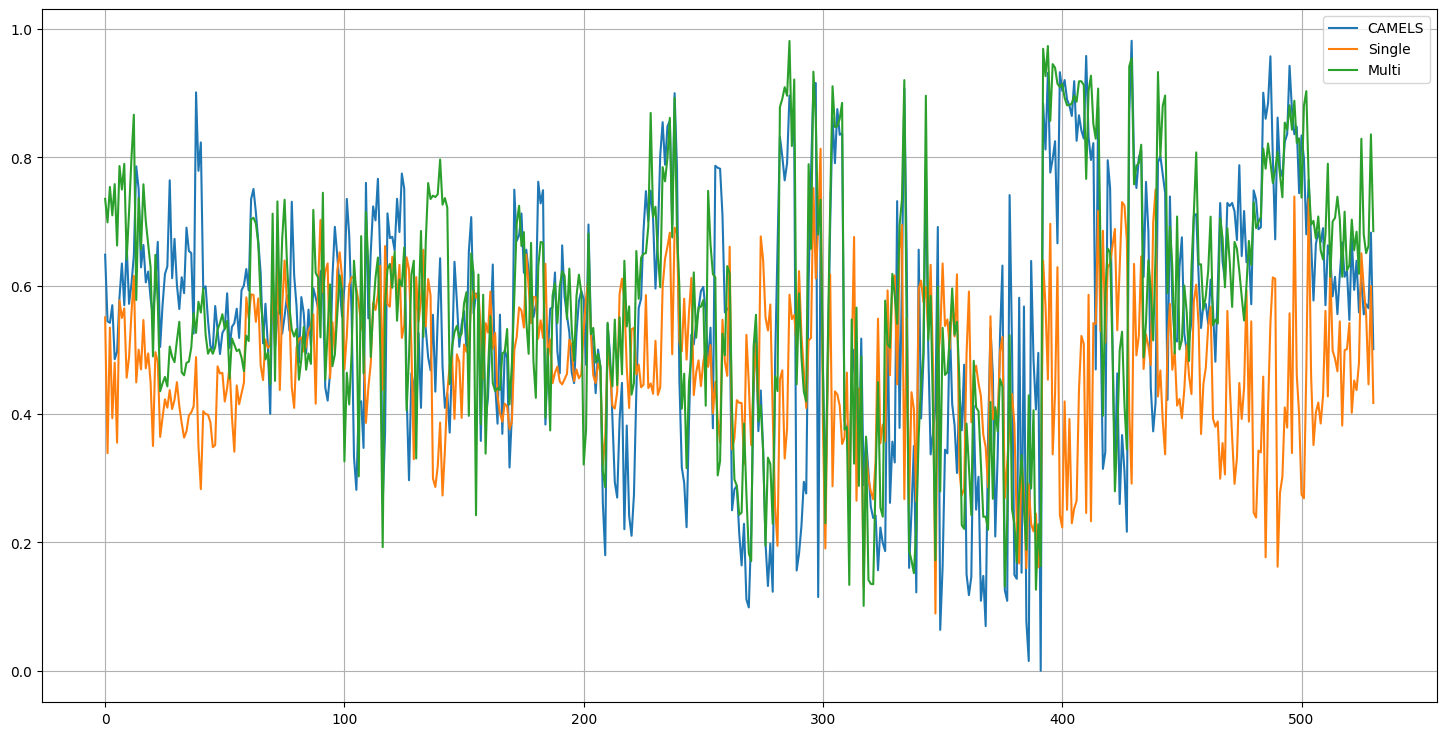

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18,9))
plt.plot(final['BFIO'],label='CAMELS')
plt.plot(final['BFIS'],label='Single')
plt.plot(final['BFIM'],label='Multi')
plt.grid()
plt.legend()
plt.show()

In [38]:
df

,gauge_id,BFIO,BFIS,BFIM
0,1013500,0.648451,0.550899,0.735480
1,1022500,0.544627,0.339102,0.698803
2,1030500,0.542262,0.534812,0.754025
3,1031500,0.569753,0.393515,0.709792
4,1047000,0.485503,0.480185,0.758493
...,...,...,...,...
526,1580000,0.555394,0.597176,0.679642
527,1583500,0.571282,0.554983,0.650835
528,1586610,0.565046,0.446344,0.662212
529,1591400,0.682859,0.599846,0.835938


In [ ]:
import pandas as pd
path= "/scratch/data/CAMELS_FORCING/camels_attributes_v2.0/camels_hydro.txt"
camels=pd.read_csv(path, sep=';')



,gauge_id,q_mean,runoff_ratio,slope_fdc,baseflow_index,stream_elas,q5,q95,high_q_freq,high_q_dur,low_q_freq,low_q_dur,zero_q_freq,hfd_mean
0,1013500,1.699155,0.543437,1.528219,0.585226,1.845324,0.241106,6.373021,6.10,8.714286,41.35,20.170732,0.000000,207.25
1,1022500,2.173062,0.602269,1.776280,0.554478,1.702782,0.204734,7.123049,3.90,2.294118,65.15,17.144737,0.000000,166.25
2,1030500,1.820108,0.555859,1.871110,0.508441,1.377505,0.107149,6.854887,12.25,7.205882,89.25,19.402174,0.000000,184.90
3,1031500,2.030242,0.576289,1.494019,0.445091,1.648693,0.111345,8.010503,18.90,3.286957,94.80,14.697674,0.000000,181.00
4,1047000,2.182870,0.656868,1.415939,0.473465,1.510238,0.196458,8.095148,14.95,2.577586,71.55,12.776786,0.000000,184.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
666,14309500,2.457700,0.493734,1.689890,0.459455,1.220096,0.057651,10.203129,41.10,4.835294,165.55,41.911392,0.000000,125.55
667,14316700,2.925937,0.643997,2.231023,0.508616,1.552484,0.141493,10.653569,16.15,2.543307,136.40,33.679012,0.000000,135.50
668,14325000,4.072283,0.646657,2.246135,0.480769,1.127976,0.104916,15.891946,23.80,3.216216,153.35,47.921875,0.000000,125.90
669,14362250,0.332015,0.119358,1.186040,0.518408,2.694495,0.000000,1.358552,33.55,9.867647,148.05,32.538462,0.088296,138.05


In [75]:
import numpy as np
import pandas as pd

ob_bfis = []
sim1_bfis = []
sim2_bfis = []

gids = []
nses1 = []
nses2 = []

nses3 = []
nses4 = []

for i in range(1, 11):

    gauge = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/baseflow.npy"
    )

    sim_flow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    ))

    sim_flow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
    ))

    sim_gwflow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    ))

    sim_gwflow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/gwflow.npy"
    ))

    for k in range(ob_baseflow.shape[1]):

        gid = int(gauge[k, 0, -2])

        # 1. Pull out the raw time series for the current basin
        raw_obs_bf = ob_baseflow[:, k]
        raw_old_bf = sim_gwflow_old[:, k]
        raw_new_bf = sim_gwflow_new[:, k]
        
        raw_obs_fl = ob_flow[:, k]
        raw_old_fl = sim_flow_old[:, k]
        raw_new_fl = sim_flow_new[:, k]

        # 2. Generate a mask tracking only the valid timesteps
        valid_mask = ~np.isnan(raw_obs_bf)

        # 3. Synchronously filter every time series using the mask
        obs_bf = raw_obs_bf[valid_mask]
        old_bf = raw_old_bf[valid_mask]
        new_bf = raw_new_bf[valid_mask]
        
        obs_fl = raw_obs_fl[valid_mask]
        old_fl = raw_old_fl[valid_mask]
        new_fl = raw_new_fl[valid_mask]

        # --- Baseflow NSE Calculation ---
        den_bf = np.sum((obs_bf - obs_bf.mean()) ** 2)

        if den_bf > 0 and len(obs_bf) > 0:
            nse1 = 1 - np.sum((obs_bf - old_bf) ** 2) / den_bf
            nse2 = 1 - np.sum((obs_bf - new_bf) ** 2) / den_bf
        else:
            nse1 = np.nan
            nse2 = np.nan

        # --- BFI Calculation (Filtered Timesteps) ---
        obs_flow_sum = np.sum(obs_fl)
        old_flow_sum = np.sum(old_fl)
        new_flow_sum = np.sum(new_fl)

        obs_bfi = np.sum(obs_bf) / obs_flow_sum if obs_flow_sum > 0 else np.nan
        old_bfi = np.sum(old_bf) / old_flow_sum if old_flow_sum > 0 else np.nan
        new_bfi = np.sum(new_bf) / new_flow_sum if new_flow_sum > 0 else np.nan

        # --- Total Flow NSE Calculation ---
        den_fl = np.sum((obs_fl - obs_fl.mean()) ** 2)

        if den_fl > 0 and len(obs_fl) > 0:
            nse3 = 1 - np.sum((obs_fl - old_fl) ** 2) / den_fl
            nse4 = 1 - np.sum((obs_fl - new_fl) ** 2) / den_fl
        else:
            nse3 = np.nan
            nse4 = np.nan

        # Append metrics to master lists
        gids.append(gid)
        nses1.append(nse1)
        nses2.append(nse2)
        nses3.append(nse3)
        nses4.append(nse4)

        ob_bfis.append(obs_bfi)
        sim1_bfis.append(old_bfi)
        sim2_bfis.append(new_bfi)

df = pd.DataFrame({
    "GaugeID": gids,
    "Observed BFI": ob_bfis,
    "Simulated BFI (Single)": sim1_bfis,
    "Simulated BFI (Multi)": sim2_bfis,
    "NSE Baseflow(Single)": nses1,
    "NSE Baseflow(Multi)": nses2,
    "NSE Flow(Single)": nses3,
    "NSE Flow(Multi)": nses4,
})
df= df.dropna()
df

,GaugeID,Observed BFI,Simulated BFI (Single),Simulated BFI (Multi),NSE Baseflow(Single),NSE Baseflow(Multi),NSE Flow(Single),NSE Flow(Multi)
0,1137500,0.508666,0.517006,0.448523,0.621423,0.788508,0.705250,0.686600
1,1181000,0.415376,0.595954,0.467844,0.333710,0.832040,0.720299,0.699458
2,1350000,0.403099,0.599309,0.522252,0.342102,0.724964,0.686715,0.661240
3,1414500,0.508553,0.663970,0.528323,0.443113,0.758105,0.663768,0.643649
4,1439500,0.556852,0.594361,0.540171,0.653555,0.770710,0.716745,0.734491
...,...,...,...,...,...,...,...,...
526,13018300,0.796774,0.830237,0.769693,0.784262,0.565990,0.792022,0.713367
527,14137000,0.618920,0.591269,0.749642,0.649684,0.598148,0.813321,0.680123
528,14236200,0.465578,0.443877,0.494840,0.582001,0.719225,0.814417,0.762640
529,14303200,0.499203,0.489653,0.410156,0.699262,0.674839,0.842157,0.843009


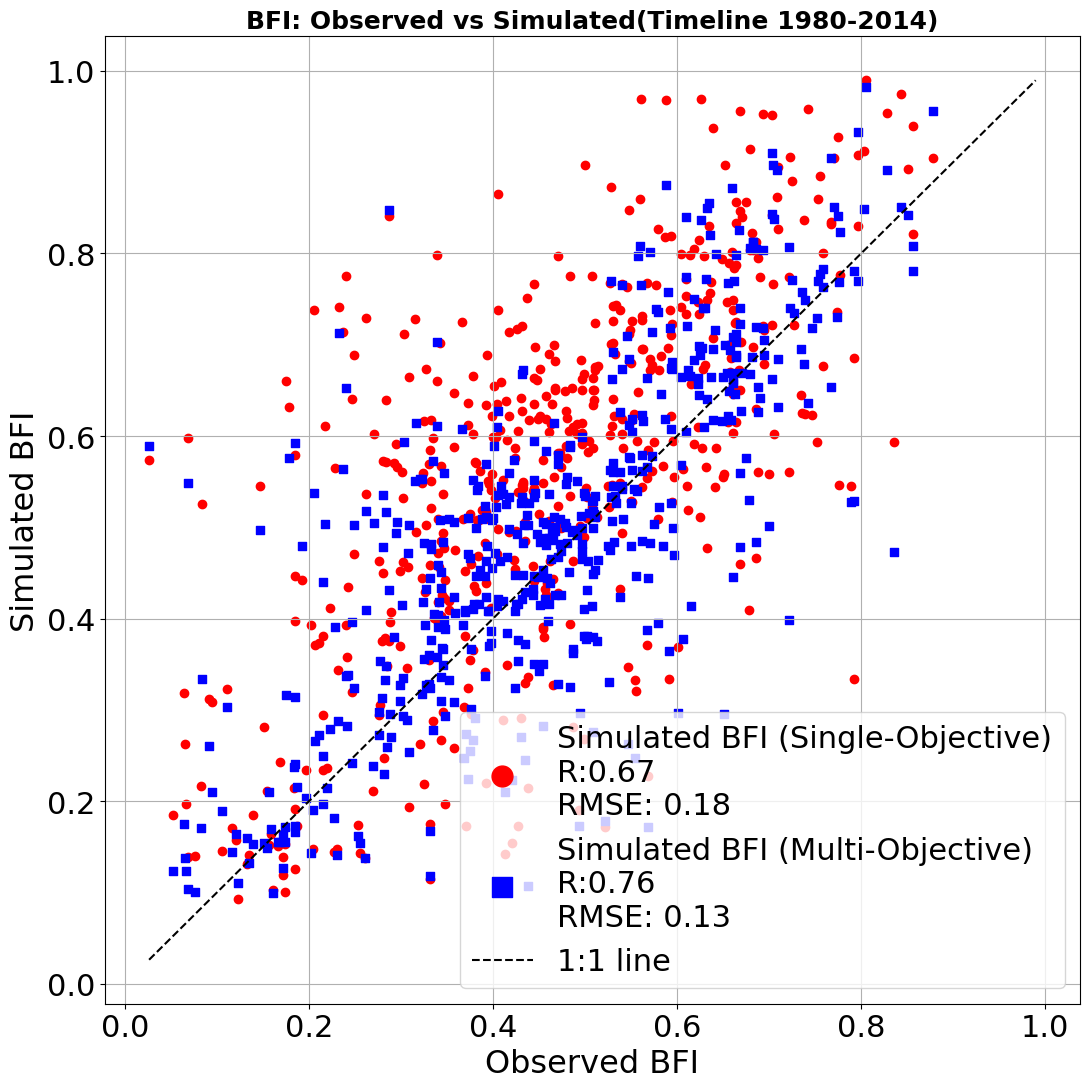

In [79]:
df= df.dropna()
import matplotlib.pyplot as plt
import numpy as np

# Extract arrays
x = df['Observed BFI'].values
y1 = df['Simulated BFI (Single)'].values
y2 = df['Simulated BFI (Multi)'].values

corr1= df['Observed BFI'].corr(df['Simulated BFI (Single)'])
rmse1= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Single)'])**2).mean())
corr2= df['Observed BFI'].corr(df['Simulated BFI (Multi)'])
rmse2= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Multi)'])**2).mean())

plt.figure(figsize=(11,11))

# Scatter plots
plt.scatter(x, y1, marker='o', label= f'Simulated BFI (Single-Objective)\nR:{corr1:.2f}\nRMSE: {rmse1:.2f}', color='red')
plt.scatter(x, y2, marker='s', label= f'Simulated BFI (Multi-Objective)\nR:{corr2:.2f}\nRMSE: {rmse2:.2f}', color='blue')

# 1:1 line
min_val = min(np.min(x), np.min(y1), np.min(y2))
max_val = max(np.max(x), np.max(y1), np.max(y2))
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='1:1 line')

# Labels and styling
plt.xlabel('Observed BFI', fontsize=23)
plt.xticks(fontsize=22)
plt.ylabel('Simulated BFI', fontsize=23)
plt.yticks(fontsize=22)
plt.title('BFI: Observed vs Simulated(Timeline 1980-2014)', fontsize=18, fontweight='bold')
plt.legend(
    fontsize=22,
    markerscale=2.5,   # Increase marker size in legend
    scatterpoints=1
)
plt.grid(True)

plt.tight_layout()
plt.show()

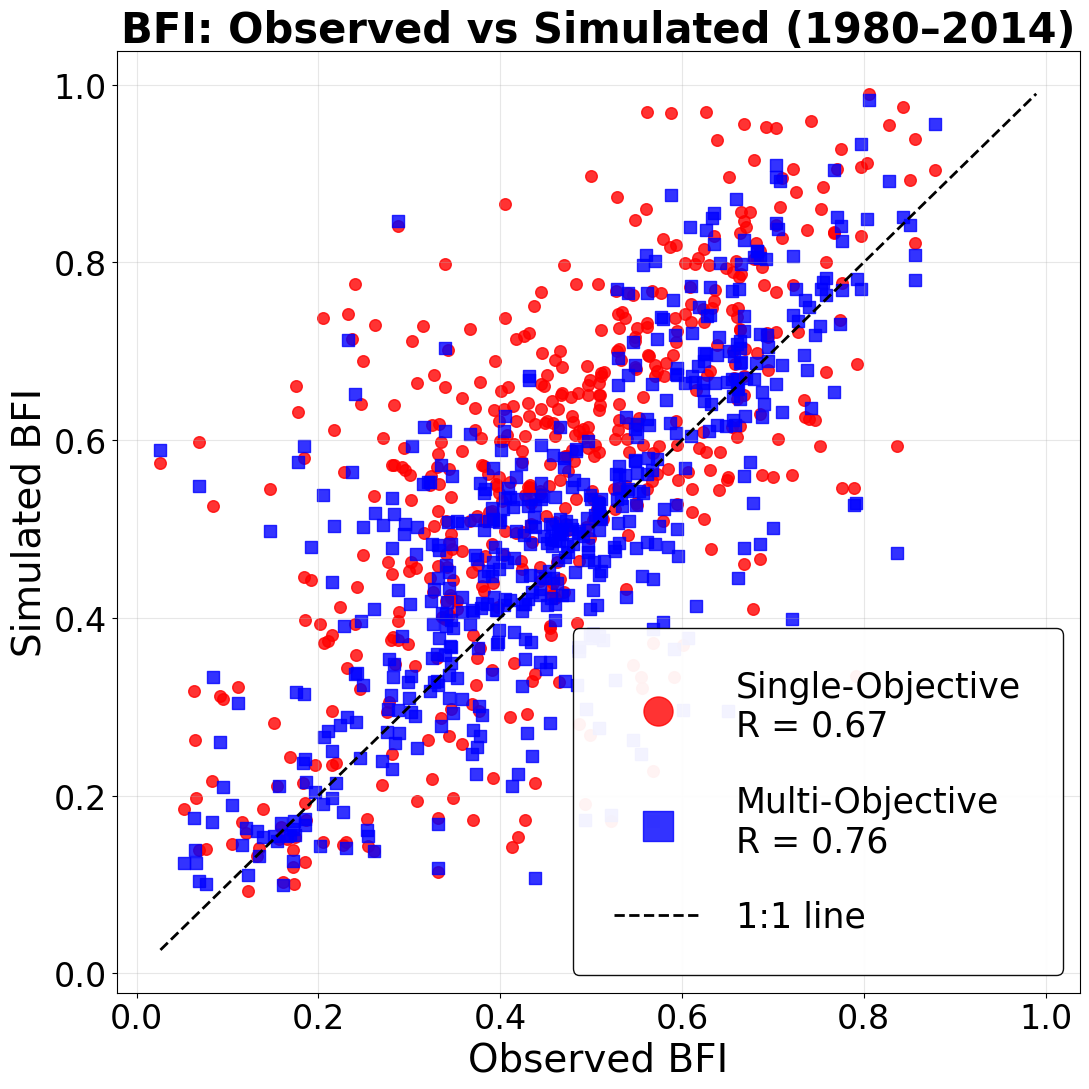

In [87]:
plt.figure(figsize=(11,11))

# Scatter plots
plt.scatter(
    x, y1,
    s=70,
    marker='o',
    color='red',
    alpha=0.8,
    label=f'Single-Objective\nR = {corr1:.2f}' #\nRMSE = {rmse1:.2f}'
)

plt.scatter(
    x, y2,
    s=70,
    marker='s',
    color='blue',
    alpha=0.8,
    label=f'Multi-Objective\nR = {corr2:.2f}' #\nRMSE = {rmse2:.2f}'
)

# 1:1 line
min_val = min(np.min(x), np.min(y1), np.min(y2))
max_val = max(np.max(x), np.max(y1), np.max(y2))
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'k--',
    lw=2,
    label='1:1 line'
)

# Labels
plt.xlabel('Observed BFI', fontsize=28)
plt.ylabel('Simulated BFI', fontsize=28)
plt.title('BFI: Observed vs Simulated (1980–2014)',
          fontsize=30,
          fontweight='bold')

plt.xticks(fontsize=24)
plt.yticks(fontsize=24)

plt.grid(alpha=0.3)

# Large publication-quality legend
plt.legend(
    fontsize=25,
    markerscale=2.5,
    handlelength=2.5,
    handletextpad=1.0,
    labelspacing=1.2,
    borderpad=1.2,
    frameon=True,
    facecolor='white',
    edgecolor='black',
    framealpha=0.95,
    loc='lower right'
)
# plt.legend(
#     fontsize=22,
#     markerscale=2.5,
#     handlelength=2.5,
#     labelspacing=1.2,
#     borderpad=1.2,
#     frameon=True,
#     edgecolor='black',
#     bbox_to_anchor=(1.02, 1),
#     loc='upper left'
# )

plt.tight_layout()
plt.savefig("BFI_Observed_Simulated_1980_2014.jpg", dpi= 500)
plt.show()

In [58]:
import numpy as np
import pandas as pd

ob_bfis = []
sim1_bfis = []
sim2_bfis = []

gids = []
nses1 = []
nses2 = []

nses3 = []
nses4 = []

for i in range(1, 11):

    gauge = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    ))

    sim_flow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    ))

    sim_gwflow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    ))

    sim_gwflow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    ))

    for k in range(ob_baseflow.shape[1]):

        gid = int(gauge[k, 0, -2])

        # 1. Pull out the raw time series for the current basin
        raw_obs_bf = ob_baseflow[:, k]
        raw_old_bf = sim_gwflow_old[:, k]
        raw_new_bf = sim_gwflow_new[:, k]
        
        raw_obs_fl = ob_flow[:, k]
        raw_old_fl = sim_flow_old[:, k]
        raw_new_fl = sim_flow_new[:, k]

        # 2. Generate a mask tracking only the valid timesteps
        valid_mask = ~np.isnan(raw_obs_bf)

        # 3. Synchronously filter every time series using the mask
        obs_bf = raw_obs_bf[valid_mask]
        old_bf = raw_old_bf[valid_mask]
        new_bf = raw_new_bf[valid_mask]
        
        obs_fl = raw_obs_fl[valid_mask]
        old_fl = raw_old_fl[valid_mask]
        new_fl = raw_new_fl[valid_mask]

        # --- Baseflow NSE Calculation ---
        den_bf = np.sum((obs_bf - obs_bf.mean()) ** 2)

        if den_bf > 0 and len(obs_bf) > 0:
            nse1 = 1 - np.sum((obs_bf - old_bf) ** 2) / den_bf
            nse2 = 1 - np.sum((obs_bf - new_bf) ** 2) / den_bf
        else:
            nse1 = np.nan
            nse2 = np.nan

        # --- BFI Calculation (Filtered Timesteps) ---
        obs_flow_sum = np.sum(obs_fl)
        old_flow_sum = np.sum(old_fl)
        new_flow_sum = np.sum(new_fl)

        obs_bfi = np.sum(obs_bf) / obs_flow_sum if obs_flow_sum > 0 else np.nan
        old_bfi = np.sum(old_bf) / old_flow_sum if old_flow_sum > 0 else np.nan
        new_bfi = np.sum(new_bf) / new_flow_sum if new_flow_sum > 0 else np.nan

        # --- Total Flow NSE Calculation ---
        den_fl = np.sum((obs_fl - obs_fl.mean()) ** 2)

        if den_fl > 0 and len(obs_fl) > 0:
            nse3 = 1 - np.sum((obs_fl - old_fl) ** 2) / den_fl
            nse4 = 1 - np.sum((obs_fl - new_fl) ** 2) / den_fl
        else:
            nse3 = np.nan
            nse4 = np.nan

        # Append metrics to master lists
        gids.append(gid)
        nses1.append(nse1)
        nses2.append(nse2)
        nses3.append(nse3)
        nses4.append(nse4)

        ob_bfis.append(obs_bfi)
        sim1_bfis.append(old_bfi)
        sim2_bfis.append(new_bfi)

df = pd.DataFrame({
    "GaugeID": gids,
    "Observed BFI": ob_bfis,
    "Simulated BFI (Single)": sim1_bfis,
    "Simulated BFI (Multi)": sim2_bfis,
    "NSE Baseflow(Single)": nses1,
    "NSE Baseflow(Multi)": nses2,
    "NSE Flow(Single)": nses3,
    "NSE Flow(Multi)": nses4,
})
df= df.dropna()
df

,GaugeID,Observed BFI,Simulated BFI (Single),Simulated BFI (Multi),NSE Baseflow(Single),NSE Baseflow(Multi),NSE Flow(Single),NSE Flow(Multi)
0,1137500,0.512035,0.516178,0.443083,0.611993,0.792758,0.625818,0.620512
1,1181000,0.423867,0.591491,0.461761,0.379054,0.857506,0.820787,0.797506
2,1350000,0.401105,0.592843,0.517640,0.473479,0.774593,0.728529,0.703480
3,1414500,0.512277,0.647505,0.533542,0.614626,0.799501,0.699731,0.678707
4,1439500,0.568313,0.606877,0.549657,0.713762,0.776999,0.722859,0.689809
...,...,...,...,...,...,...,...,...
526,13018300,0.790706,0.797710,0.729036,0.828870,0.625679,0.833579,0.823682
527,14137000,0.600912,0.574998,0.704958,0.680521,0.565983,0.860354,0.751692
528,14236200,0.455369,0.465651,0.462894,0.669652,0.735508,0.842158,0.805702
529,14303200,0.474456,0.437595,0.373342,0.643902,0.616248,0.865610,0.865293


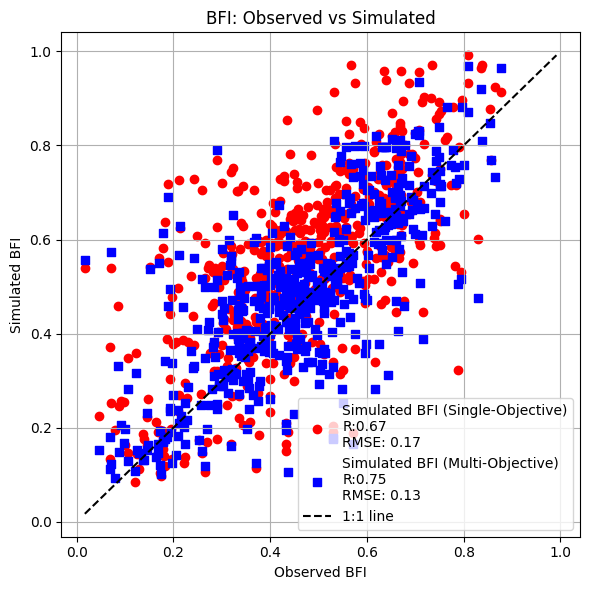

In [55]:
df= df.dropna()
import matplotlib.pyplot as plt
import numpy as np

# Extract arrays
x = df['Observed BFI'].values
y1 = df['Simulated BFI (Single)'].values
y2 = df['Simulated BFI (Multi)'].values

corr1= df['Observed BFI'].corr(df['Simulated BFI (Single)'])
rmse1= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Single)'])**2).mean())
corr2= df['Observed BFI'].corr(df['Simulated BFI (Multi)'])
rmse2= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Multi)'])**2).mean())

plt.figure(figsize=(6,6))

# Scatter plots
plt.scatter(x, y1, marker='o', label= f'Simulated BFI (Single-Objective)\nR:{corr1:.2f}\nRMSE: {rmse1:.2f}', color='red')
plt.scatter(x, y2, marker='s', label= f'Simulated BFI (Multi-Objective)\nR:{corr2:.2f}\nRMSE: {rmse2:.2f}', color='blue')

# 1:1 line
min_val = min(np.min(x), np.min(y1), np.min(y2))
max_val = max(np.max(x), np.max(y1), np.max(y2))
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='1:1 line')

# Labels and styling
plt.xlabel('Observed BFI')
plt.ylabel('Simulated BFI')
plt.title('BFI: Observed vs Simulated')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

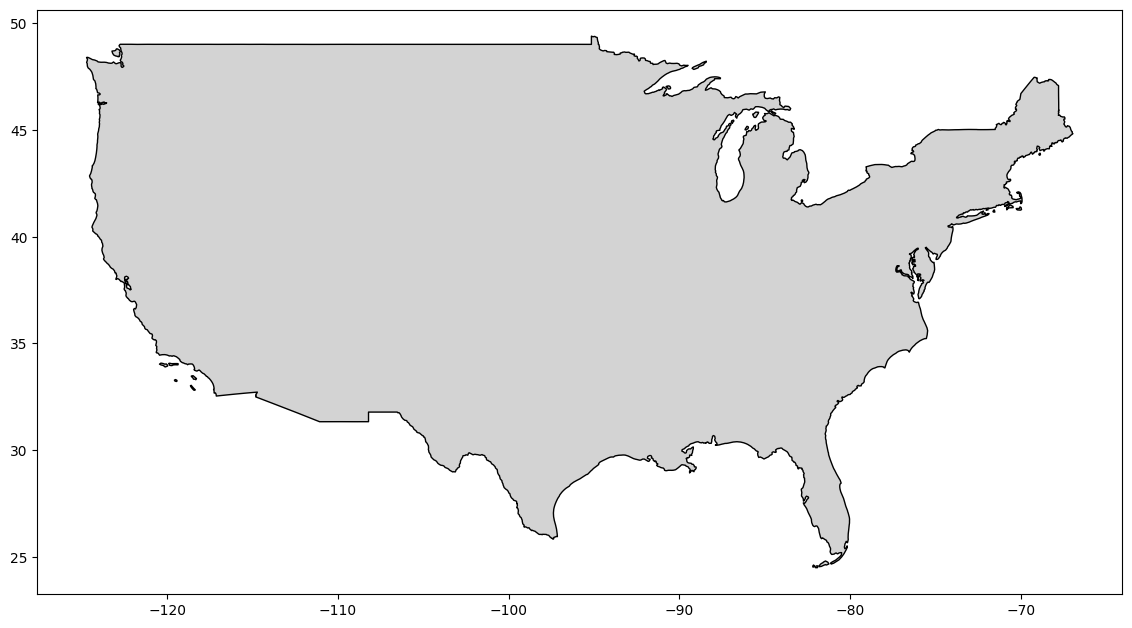

In [61]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Plot the clipped map
fig, ax = plt.subplots(figsize=(14, 14))
gdf_conus.plot(ax=ax, edgecolor="black", color="lightgray")
plt.show()

In [ ]:
# import pandas as pd

# # Load using exact tab characters, skipping bad rows if they exist
# locations = pd.read_csv(
#     "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt",
#     sep="\t",
#     dtype={"GAGE_ID": str, "HUC_02": str},
#     on_bad_lines='skip'
# )

# # Clean up column names in case they have leading/trailing whitespace
# locations.columns = locations.columns.str.strip()

# # Display the clean dataframe
##### locations.to_csv('gauge_loc.csv')

In [7]:
import numpy as np
import pandas as pd
def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den
locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")

metrics = {
    "GageID": [],
    "NSE-Flow (Single-Objective)": [],
    "NSE-Flow (Multi-Objective)": [],
    "NSE-Baseflow (Single-Objective)": [],
    "NSE-Baseflow (Multi-Objective)": [],
    "lat": [],
    "lon": []
}

for i in range(1, 11):

    gauge = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    sim_flow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_flow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_flow_old = np.squeeze(sim_flow_old)
    sim_flow_new = np.squeeze(sim_flow_new)
    sim_gwflow_old = np.squeeze(sim_gwflow_old)
    sim_gwflow_new = np.squeeze(sim_gwflow_new)

    # --------------------------------------------------------
    # Loop over basins
    # --------------------------------------------------------
    for k in range(ob_flow.shape[1]):

        

        gid = int(gauge[k, 0, -2])

        matching_row = locations[locations['GAGE_ID'] == gid]
        lat = matching_row['LAT'].item()
        lon = matching_row['LONG'].item()
        # lat= locations.loc[f'{gid}',['LAT']]
        # lon= locations.loc[f'{gid}',['LONG']]

        metrics["GageID"].append(gid)
        metrics["lat"].append(lat)
        metrics["lon"].append(lon)

        ## Baseflow
        obs = ob_baseflow[:, k]
        old = sim_gwflow_old[:, k]
        new = sim_gwflow_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
        metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

        ## Flow
        obs = ob_flow[:, k]
        old = sim_flow_old[:, k]
        new = sim_flow_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
        metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
table = pd.DataFrame(metrics)
table

,GageID,NSE-Flow (Single-Objective),NSE-Flow (Multi-Objective),NSE-Baseflow (Single-Objective),NSE-Baseflow (Multi-Objective),lat,lon
0,1137500,0.625818,0.620512,0.611993,0.792758,44.26867,-71.63036
1,1181000,0.820787,0.797506,0.379054,0.857506,42.23731,-72.89565
2,1350000,0.728529,0.703480,0.473479,0.774593,42.31953,-74.43654
3,1414500,0.699731,0.678707,0.614626,0.799501,42.10620,-74.73043
4,1439500,0.722859,0.689809,0.713762,0.776999,41.08815,-75.03767
...,...,...,...,...,...,...,...
526,13018300,0.833579,0.823682,0.828870,0.625679,43.45215,-110.70409
527,14137000,0.860354,0.751692,0.680521,0.565983,45.39956,-122.13731
528,14236200,0.842158,0.805702,0.669652,0.735508,46.59538,-122.45956
529,14303200,0.865610,0.865293,0.643902,0.616248,45.32428,-123.54650


/tmp/ipykernel_80955/1879606396.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


TypeError: FigureBase.colorbar() missing 1 required positional argument: 'mappable'

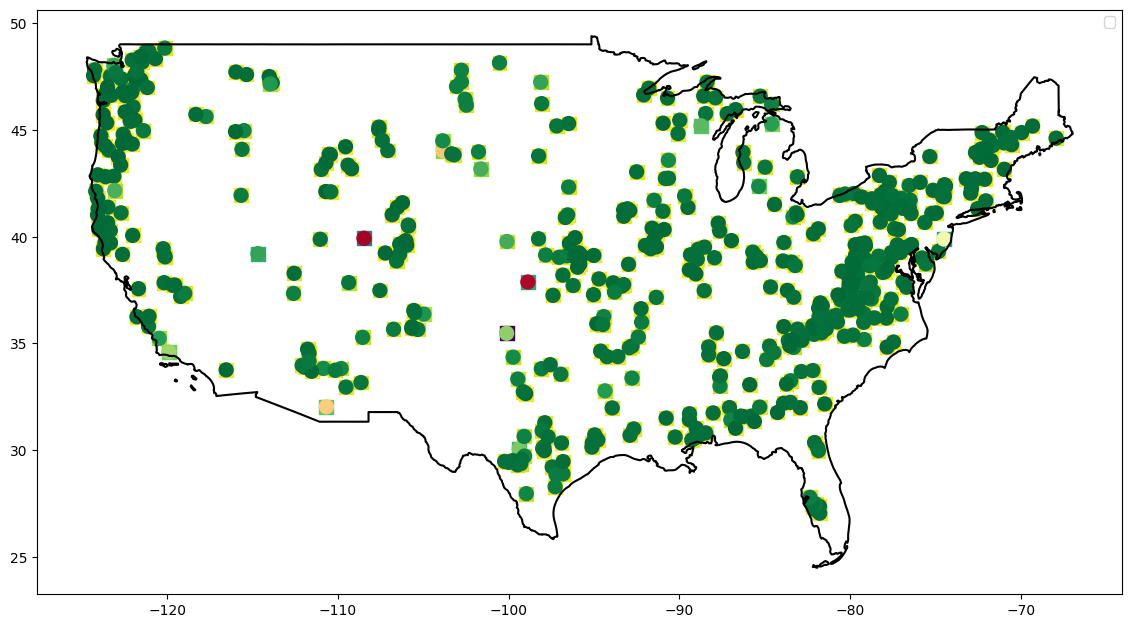

In [153]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Plot the clipped map
fig, ax = plt.subplots(figsize=(14, 14))

ax.scatter(table['lon'],table['lat'], marker='s', s=100, c=table['NSE-Flow (Single-Objective)'], cmap='viridis')
ax.scatter(table['lon'],table['lat'], marker='o', s=100, c=table['NSE-Flow (Multi-Objective)'], cmap='RdYlGn')
gdf_conus.boundary.plot(ax=ax, edgecolor="black")
plt.legend()
fig.colorbar()
plt.show()

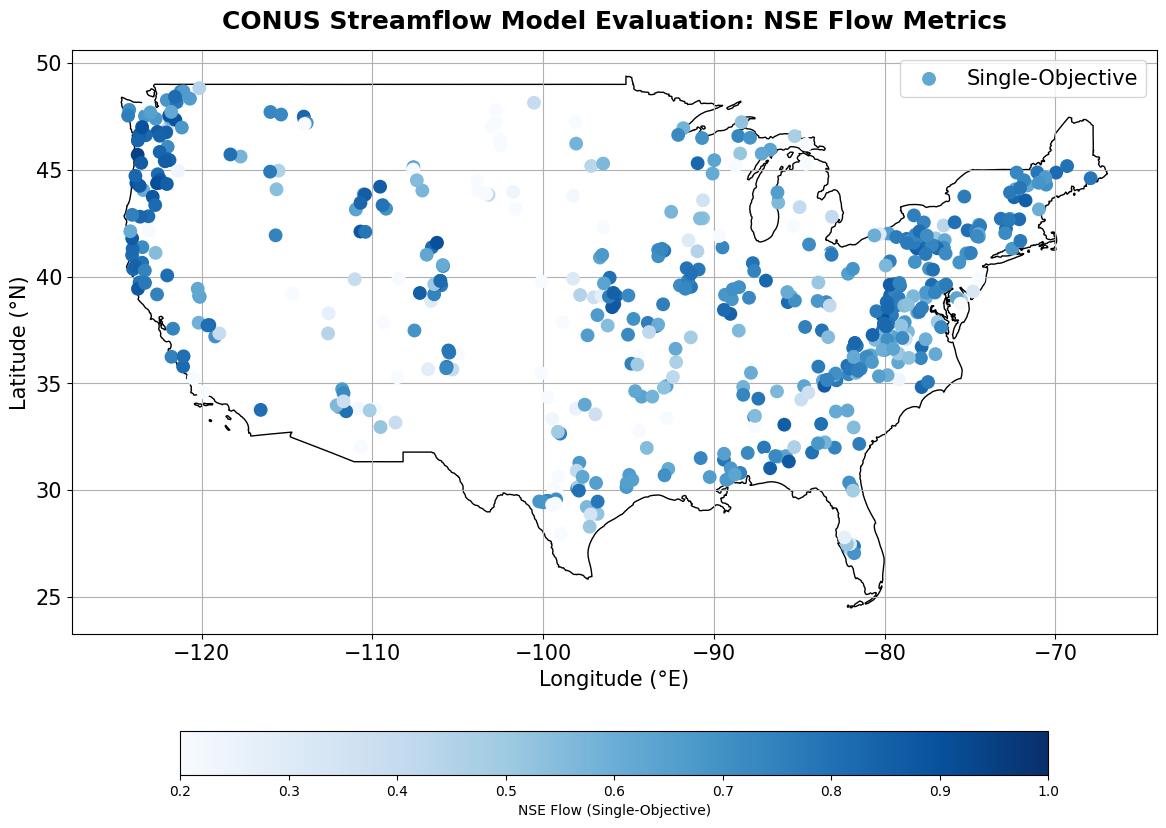

In [237]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# 2. Plot Single-Objective performance markers (Square shape)
scatter1 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c=table['NSE-Flow (Single-Objective)'], 
    cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
    label='Single-Objective', zorder=2
)

# # 3. Plot Multi-Objective performance markers (Circle shape)
# scatter2 = ax.scatter(
#     table['lon'], table['lat'], 
#     marker='o', s=80, 
#     c=table['NSE-Flow (Multi-Objective)'], 
#     cmap='RdYlGn', vmin=0, vmax=1,
#     label='Multi-Objective', zorder=3
# )

# 4. Generate discrete colorbars for both objectives
cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar1.set_label('NSE Flow (Single-Objective)')

# cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.12, shrink=0.4)
# cbar2.set_label('NSE Flow (Multi-Objective)')

# 5. Finalize legend and axis view configurations
plt.legend(loc='upper right', fontsize=15)
ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
# ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
plt.ylabel('Latitude (°N)', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid()
plt.show()


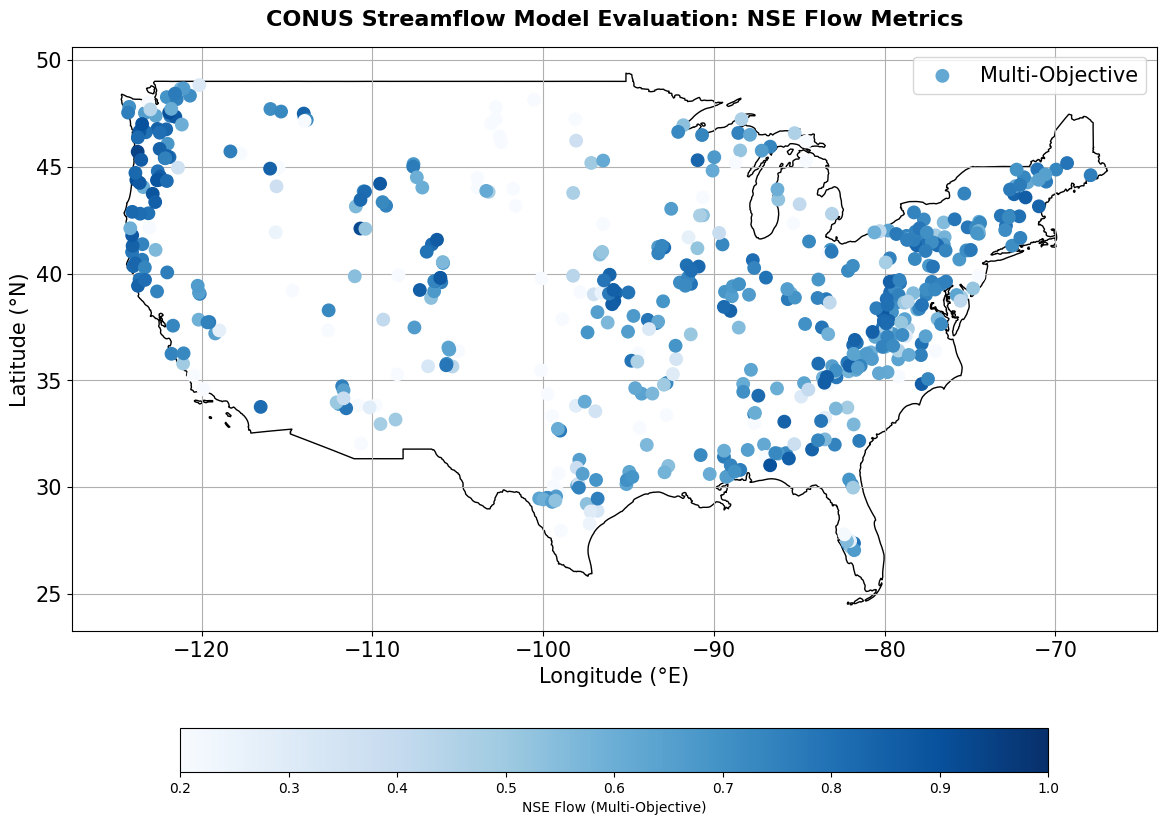

In [238]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# # 2. Plot Single-Objective performance markers (Square shape)
# scatter1 = ax.scatter(
#     table['lon'], table['lat'], 
#     marker='s', s=80, 
#     c=table['NSE-Flow (Single-Objective)'], 
#     cmap='viridis', vmin=0, vmax=1,  # Set color limits for clear NSE comparison
#     label='Single-Objective', zorder=2
# )

# 3. Plot Multi-Objective performance markers (Circle shape)
scatter2 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c=table['NSE-Flow (Multi-Objective)'], 
    cmap='Blues', vmin=0.2, vmax=1,
    label='Multi-Objective', zorder=3
)

# 4. Generate discrete colorbars for both objectives
# cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.05, shrink=0.4)
# cbar1.set_label('NSE Flow (Single-Objective)')

cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar2.set_label('NSE Flow (Multi-Objective)')

# 5. Finalize legend and axis view configurations
plt.legend(loc='upper right', fontsize=15)
ax.set_title("CONUS Streamflow Model Evaluation: NSE Flow Metrics", fontsize=16, fontweight='bold', pad=15)
# ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
plt.ylabel('Latitude (°N)', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid()
plt.show()


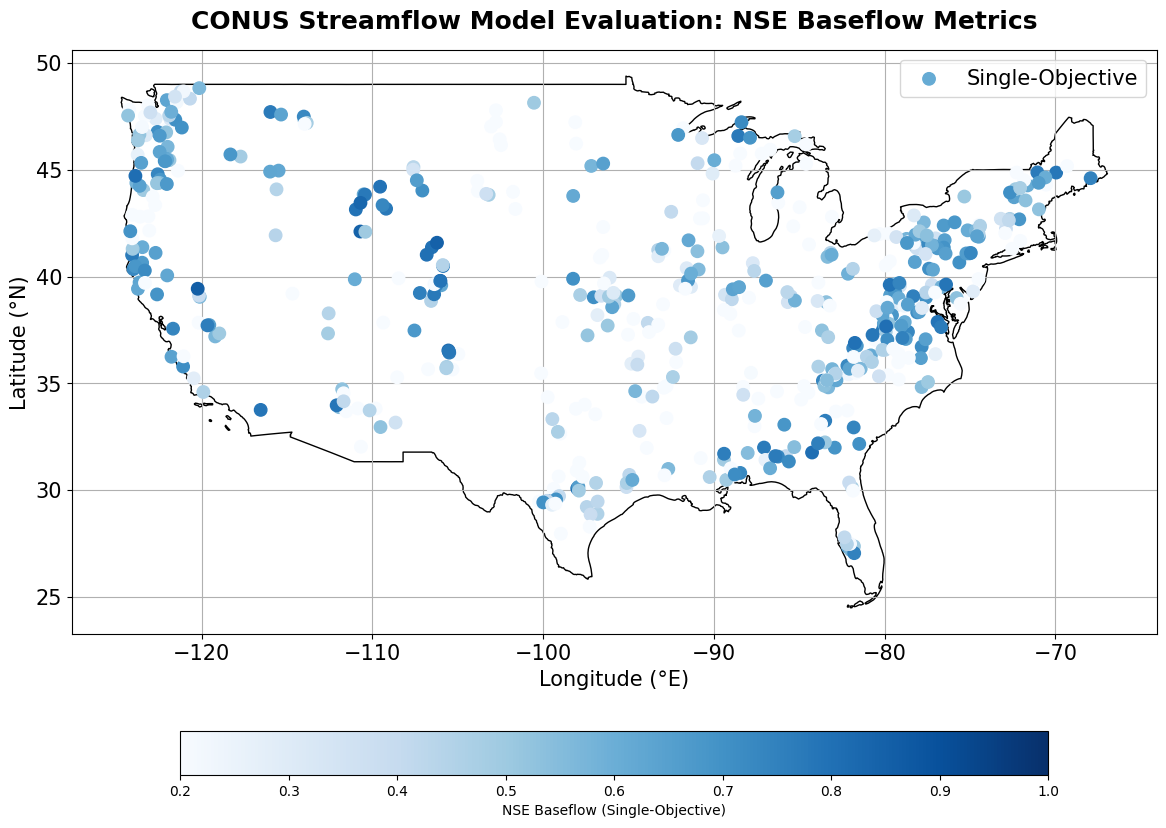

In [240]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# 2. Plot Single-Objective performance markers (Square shape)
scatter1 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c=table['NSE-Baseflow (Single-Objective)'], 
    cmap='Blues', vmin=0.2, vmax=1,  # Set color limits for clear NSE comparison
    label='Single-Objective', zorder=2
)

# # 3. Plot Multi-Objective performance markers (Circle shape)
# scatter2 = ax.scatter(
#     table['lon'], table['lat'], 
#     marker='o', s=80, 
#     c=table['NSE-Flow (Multi-Objective)'], 
#     cmap='RdYlGn', vmin=0, vmax=1,
#     label='Multi-Objective', zorder=3
# )

# 4. Generate discrete colorbars for both objectives
cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar1.set_label('NSE Baseflow (Single-Objective)')

# cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.12, shrink=0.4)
# cbar2.set_label('NSE Flow (Multi-Objective)')

# 5. Finalize legend and axis view configurations
plt.legend(loc='upper right', fontsize=15)
ax.set_title("CONUS Streamflow Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
# ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
plt.ylabel('Latitude (°N)', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid()
plt.show()


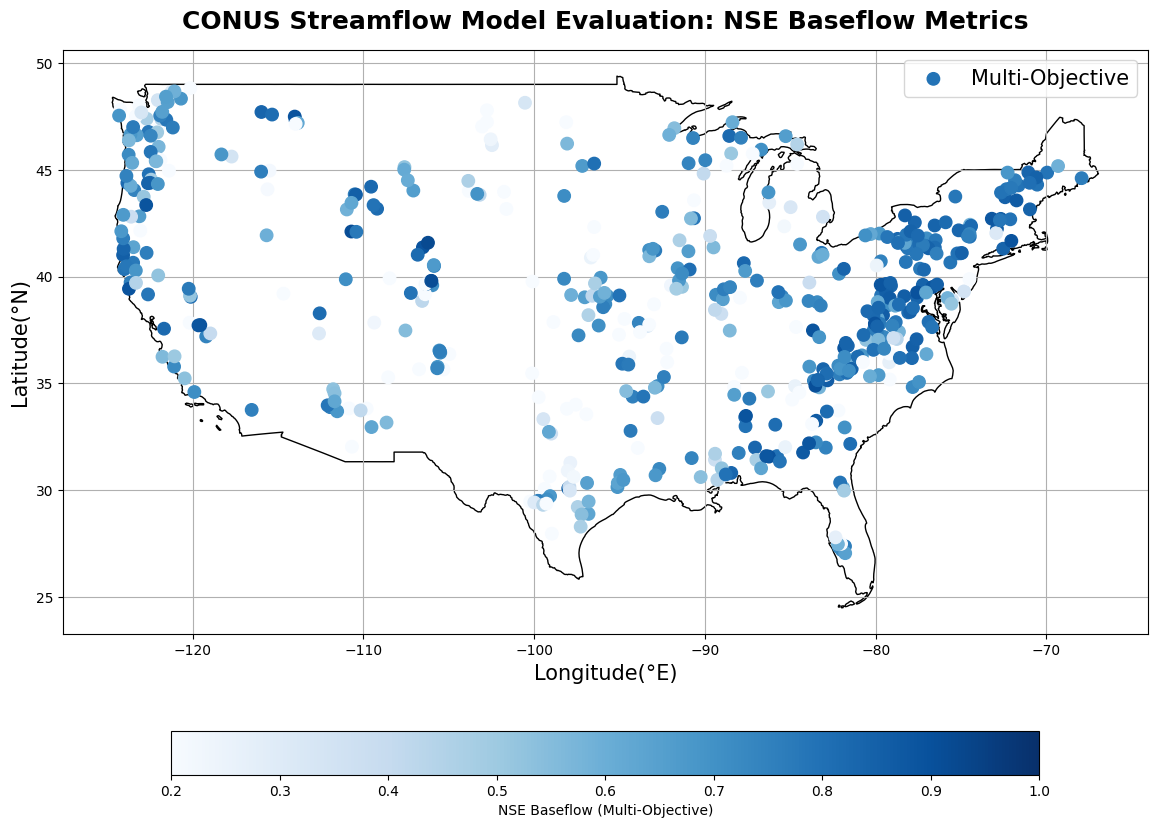

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# # 2. Plot Single-Objective performance markers (Square shape)
# scatter1 = ax.scatter(
#     table['lon'], table['lat'], 
#     marker='s', s=80, 
#     c=table['NSE-Flow (Single-Objective)'], 
#     cmap='viridis', vmin=0, vmax=1,  # Set color limits for clear NSE comparison
#     label='Single-Objective', zorder=2
# )

# 3. Plot Multi-Objective performance markers (Circle shape)
scatter2 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c=table['NSE-Baseflow (Multi-Objective)'], 
    cmap='Blues', vmin=0.2, vmax=1,
    label='Multi-Objective', zorder=3
)

# 4. Generate discrete colorbars for both objectives
# cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.05, shrink=0.4)
# cbar1.set_label('NSE Flow (Single-Objective)')

cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar2.set_label('NSE Baseflow (Multi-Objective)')

# 5. Finalize legend and axis view configurations
plt.legend(loc='upper right', fontsize=15)
ax.set_title("CONUS Model Evaluation: NSE Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
# ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
plt.xlabel('Longitude(°E)', fontsize=15)
plt.ylabel('Latitude(°N)', fontsize=15)
plt.grid()
plt.show()


NameError: name 'table' is not defined

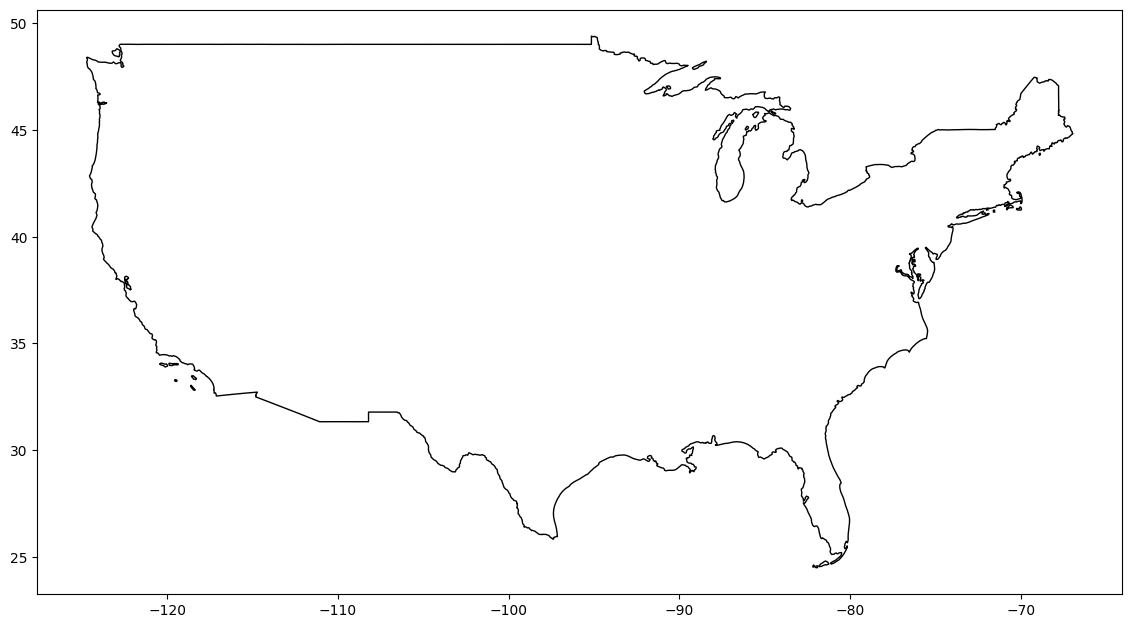

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# 2. Plot performance markers
scatter1 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c=(table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']), 
    cmap='seismic_r', 
    vmin=-0.4, 
    vmax=0.4,  
    label=r'$\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}}$', 
    zorder=2
)

# 4. Generate discrete colorbar
cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar1.set_label(r'$\Delta\text{NSE}\ (\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}})$', fontsize=14)
cbar1.ax.tick_params(labelsize=12)

# 5. Finalize legend and axis view configurations
leg = plt.legend(loc='upper right', fontsize=14, framealpha=1.0, facecolor='white', edgecolor='gray')

# FORCE LEGEND ICON COLOR TO BE VISIBLE (Changes it from invisible white to solid dark blue/grey)
for handle in leg.legend_handles:
    handle.set_color('#1f77b4')  # Solid blue color for the legend reference circle
    handle.set_sizes([100])      # Makes the legend circle slightly larger for readability

ax.set_title("CONUS Streamflow Model Evaluation: Change in NSE Flow Metrics", fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Longitude (°E)', fontsize=15)  # Corrected to °W for CONUS coordinates
plt.ylabel('Latitude (°N)', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid()
plt.show()

NameError: name 'table' is not defined

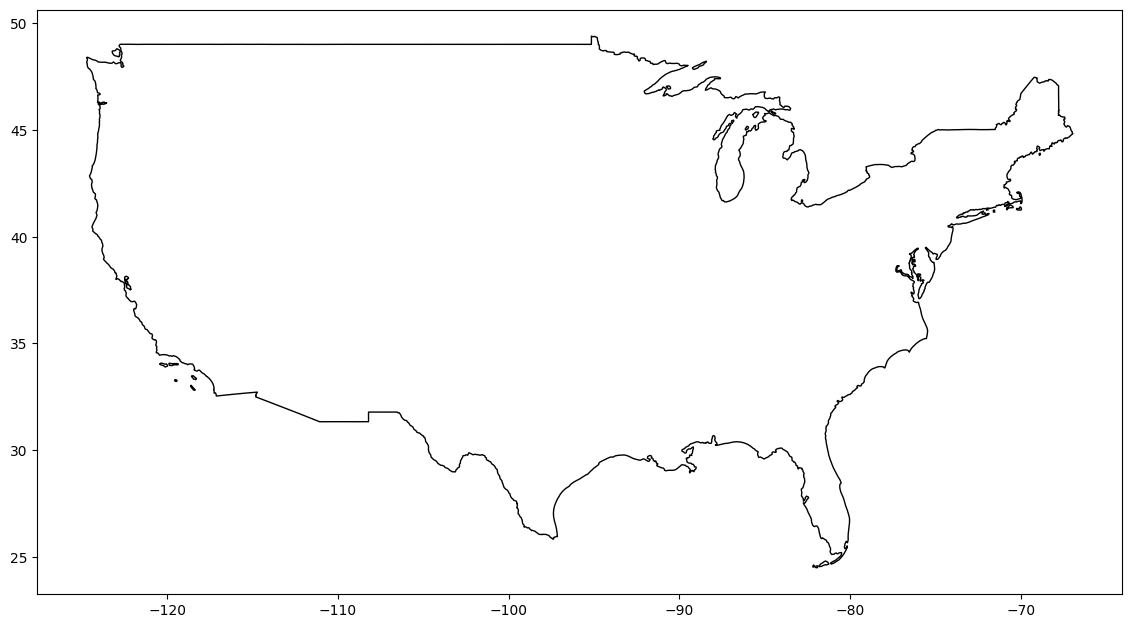

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)

# Create the plot figure
fig, ax = plt.subplots(figsize=(14, 14))

# 1. Plot the map outline backdrop first
gdf_conus.boundary.plot(ax=ax, edgecolor="black", linewidth=1, zorder=1)

# 2. Plot Single-Objective performance markers (Square shape)
scatter1 = ax.scatter(
    table['lon'], table['lat'], 
    marker='o', s=80, 
    c= (table['NSE-Baseflow (Multi-Objective)']-table['NSE-Baseflow (Single-Objective)']), 
    cmap='seismic_r', 
    vmin=-0.4, 
    vmax=0.4,  # Set color limits for clear NSE comparison
    label= r'$\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}}$',
    zorder= 2)

# # 3. Plot Multi-Objective performance markers (Circle shape)
# scatter2 = ax.scatter(
#     table['lon'], table['lat'], 
#     marker='o', s=80, 
#     c=table['NSE-Flow (Multi-Objective)'], 
#     cmap='RdYlGn', vmin=0, vmax=1,
#     label='Multi-Objective', zorder=3
# )

# 4. Generate discrete colorbars for both objectives
cbar1 = fig.colorbar(scatter1, ax=ax, orientation='horizontal', pad=0.09, shrink=0.8)
cbar1.set_label(r'$\Delta\text{NSE}\ (\text{NSE}_{\mathit{multi}} - \text{NSE}_{\mathit{single}})$', fontsize=14)

# cbar2 = fig.colorbar(scatter2, ax=ax, orientation='horizontal', pad=0.12, shrink=0.4)
# cbar2.set_label('NSE Flow (Multi-Objective)')

# 5. Finalize legend and axis view configurations
plt.legend(loc='upper right', fontsize=15)
ax.set_title("CONUS Streamflow Model Evaluation: Change in Baseflow Metrics", fontsize=18, fontweight='bold', pad=15)
# ax.set_axis_off()  # Optional: hides degree grid lines for a cleaner look
plt.xlabel('Longitude(°E)', fontsize=15)
plt.ylabel('Latitude(°N)', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid()
plt.show()